# Cross-Country Generalization — YOLOv8s on RDD2022

Train **YOLOv8s only on Japanese road images** and test the resulting `best.pt` on:
Japan, India, Czech, Norway, China, and United States.

Settings: 50 epochs, 640 image size, batch 16, patience 15, seed 42.


## 1. Setup

Imports, the training settings (the same as the main experiment: 50 epochs, image size 640, batch size 16, patience 15, seed 42) and the dataset paths.

In [10]:
# CELL 1 — Imports and environment
import os, random, shutil, platform, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if not torch.cuda.is_available():
    raise RuntimeError("Enable a Kaggle GPU before training.")

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


Python: 3.12.13
PyTorch: 2.10.0+cu128
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [11]:
# CELL 2 — Configuration
SEED = 42
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16
PATIENCE = 15
WORKERS = 2
DEVICE = 0

MODEL_NAME = "yolov8s.pt"
RUN_NAME = "YOLOv8s_JapanOnly_50epochs"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Patience:", PATIENCE)
print("Seed:", SEED)


Epochs: 50
Image size: 640
Batch size: 16
Patience: 15
Seed: 42


In [12]:
# CELL 3 — Paths
SOURCE_DATASET = Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT")
WORKING_ROOT = Path("/kaggle/working")
COUNTRY_DATASET = WORKING_ROOT / "RDD_Japan_Generalization"

TRAIN_IMAGES = COUNTRY_DATASET / "train" / "images"
TRAIN_LABELS = COUNTRY_DATASET / "train" / "labels"
VAL_IMAGES = COUNTRY_DATASET / "val" / "images"
VAL_LABELS = COUNTRY_DATASET / "val" / "labels"

TEST_COUNTRIES = ["Japan", "India", "Czech", "Norway", "China", "United"]

PROJECT_DIR = WORKING_ROOT / "RoadDamageProject"
RUN_DIR = PROJECT_DIR / RUN_NAME
MAIN_YAML = WORKING_ROOT / "japan_only_train.yaml"

print("Source:", SOURCE_DATASET)
print("Generated dataset:", COUNTRY_DATASET)
print("Run:", RUN_DIR)


Source: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT
Generated dataset: /kaggle/working/RDD_Japan_Generalization
Run: /kaggle/working/RoadDamageProject/YOLOv8s_JapanOnly_50epochs


## 2. Build the Japan-only dataset

Checks the source dataset and counts the images per country (the country is read from the start of each file name). Then copies Japan's train and validation images into a new dataset, copies each country's test images into its own test folder, checks the copied counts and writes the training YAML.

In [13]:
# CELL 4 — Verify source dataset
required = []
for split in ["train", "val", "test"]:
    required += [
        SOURCE_DATASET / split / "images",
        SOURCE_DATASET / split / "labels"
    ]

for p in required:
    print(p, "->", p.exists())

if not all(p.exists() for p in required):
    raise FileNotFoundError("RDD2022 split folders are incomplete.")


/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/images -> True
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/labels -> True
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images -> True
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels -> True
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images -> True
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/labels -> True


In [14]:
# CELL 5 — Country distribution
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
rows = []

for split in ["train", "val", "test"]:
    counts = Counter()
    for image_path in (SOURCE_DATASET / split / "images").iterdir():
        if image_path.suffix.lower() in IMAGE_EXTENSIONS:
            country = image_path.stem.split("_")[0]
            counts[country] += 1

    for country, count in sorted(counts.items()):
        rows.append({"Split": split, "Country": country, "Images": count})

country_distribution = pd.DataFrame(rows)
distribution_table = country_distribution.pivot(
    index="Country", columns="Split", values="Images"
).fillna(0).astype(int)

display(distribution_table)


Split,test,train,val
Country,,,
China,682,3051,645
Czech,436,1962,431
India,1166,5368,1172
Japan,1524,7432,1550
Norway,1197,5708,1256
United,753,3348,704


In [15]:
# CELL 6 — Helper to copy one country subset
def copy_country_subset(source_split, country_prefix, destination_images, destination_labels):
    source_images = SOURCE_DATASET / source_split / "images"
    source_labels = SOURCE_DATASET / source_split / "labels"

    destination_images.mkdir(parents=True, exist_ok=True)
    destination_labels.mkdir(parents=True, exist_ok=True)

    copied_images = 0
    copied_labels = 0
    missing_labels = 0

    for image_path in source_images.iterdir():
        if image_path.suffix.lower() in IMAGE_EXTENSIONS and image_path.stem.startswith(country_prefix + "_"):
            shutil.copy2(image_path, destination_images / image_path.name)
            copied_images += 1

            label_path = source_labels / f"{image_path.stem}.txt"
            if label_path.exists():
                shutil.copy2(label_path, destination_labels / label_path.name)
                copied_labels += 1
            else:
                missing_labels += 1

    return {
        "Country": country_prefix,
        "Source split": source_split,
        "Images": copied_images,
        "Labels": copied_labels,
        "Missing labels": missing_labels,
    }


In [16]:
# CELL 7 — Create Japan train/val and country-specific tests
if COUNTRY_DATASET.exists():
    shutil.rmtree(COUNTRY_DATASET)

summary = []

summary.append(copy_country_subset(
    "train", "Japan", TRAIN_IMAGES, TRAIN_LABELS
))

summary.append(copy_country_subset(
    "val", "Japan", VAL_IMAGES, VAL_LABELS
))

for country in TEST_COUNTRIES:
    summary.append(copy_country_subset(
        "test",
        country,
        COUNTRY_DATASET / f"test_{country.lower()}" / "images",
        COUNTRY_DATASET / f"test_{country.lower()}" / "labels",
    ))

creation_summary = pd.DataFrame(summary)
display(creation_summary)


,Country,Source split,Images,Labels,Missing labels
0,Japan,train,7432,7432,0
1,Japan,val,1550,1550,0
2,Japan,test,1524,1524,0
3,India,test,1166,1166,0
4,Czech,test,436,436,0
5,Norway,test,1197,1197,0
6,China,test,682,682,0
7,United,test,753,753,0


In [17]:
# CELL 8 — Verify generated subset counts
rows = [
    {
        "Subset": "train_japan",
        "Images": len(list(TRAIN_IMAGES.iterdir())),
        "Labels": len(list(TRAIN_LABELS.glob("*.txt")))
    },
    {
        "Subset": "val_japan",
        "Images": len(list(VAL_IMAGES.iterdir())),
        "Labels": len(list(VAL_LABELS.glob("*.txt")))
    }
]

for country in TEST_COUNTRIES:
    img_dir = COUNTRY_DATASET / f"test_{country.lower()}" / "images"
    lbl_dir = COUNTRY_DATASET / f"test_{country.lower()}" / "labels"
    rows.append({
        "Subset": f"test_{country.lower()}",
        "Images": len(list(img_dir.iterdir())),
        "Labels": len(list(lbl_dir.glob("*.txt")))
    })

verification_df = pd.DataFrame(rows)
display(verification_df)


,Subset,Images,Labels
0,train_japan,7432,7432
1,val_japan,1550,1550
2,test_japan,1524,1524
3,test_india,1166,1166
4,test_czech,436,436
5,test_norway,1197,1197
6,test_china,682,682
7,test_united,753,753


In [18]:
# CELL 9 — Create Japan-only training YAML
training_yaml = {
    "path": str(COUNTRY_DATASET),
    "train": "train/images",
    "val": "val/images",
    "nc": 5,
    "names": [
        "longitudinal crack",
        "transverse crack",
        "alligator crack",
        "other corruption",
        "Pothole",
    ],
}

with open(MAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(training_yaml, f, sort_keys=False)

print(MAIN_YAML.read_text())


path: /kaggle/working/RDD_Japan_Generalization
train: train/images
val: val/images
nc: 5
names:
- longitudinal crack
- transverse crack
- alligator crack
- other corruption
- Pothole



## 3. Train YOLOv8s on Japan only

Installs Ultralytics, clears any old run with the same name, trains YOLOv8s on the Japanese images only, then checks the training outputs and shows the training plots.

In [19]:
# CELL 10 — Install/import Ultralytics
!pip install -q ultralytics

import ultralytics
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 709.1 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.9/63.9 kB 4.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics: 8.4.120


In [20]:
# CELL 11 — Clear only an old run with the same name
if RUN_DIR.exists():
    shutil.rmtree(RUN_DIR)
    print("Removed old run:", RUN_DIR)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print("Ready for fresh training.")


Ready for fresh training.


In [21]:
# CELL 12 — Train YOLOv8s on Japan only
model = YOLO(MODEL_NAME)

start = time.time()

train_results = model.train(
    data=str(MAIN_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    patience=PATIENCE,
    seed=SEED,
    deterministic=True,
    pretrained=True,
    device=DEVICE,
    amp=True,
    cache=False,
    save=True,
    save_period=5,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=False,
)

training_hours = (time.time() - start) / 3600
print(f"Training time: {training_hours:.2f} hours")
print("Run directory:", RUN_DIR)


Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/japan_only_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8s_JapanOnly_50epo

In [22]:
# CELL 13 — Verify training outputs
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"
RESULTS_CSV = RUN_DIR / "results.csv"

print("best.pt:", BEST_WEIGHTS.exists())
print("last.pt:", LAST_WEIGHTS.exists())
print("results.csv:", RESULTS_CSV.exists())

if RESULTS_CSV.exists():
    train_df = pd.read_csv(RESULTS_CSV)
    print("Completed epochs:", len(train_df))
    display(train_df.tail())

if not BEST_WEIGHTS.exists():
    raise FileNotFoundError("best.pt was not produced.")


best.pt: True
last.pt: True
results.csv: True
Completed epochs: 50


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
45,46,6566.80,1.37094,1.10408,1.38466,0.61704,0.57484,0.60298,0.30493,1.64173,1.32325,1.55326,0.000121,0.000121,0.000121
46,47,6709.12,1.35730,1.07838,1.37686,0.62758,0.57830,0.60656,0.30729,1.65023,1.31800,1.56138,0.000099,0.000099,0.000099
47,48,6850.95,1.34376,1.05796,1.36831,0.63477,0.56459,0.60733,0.30747,1.65439,1.32154,1.56883,0.000077,0.000077,0.000077
48,49,6992.53,1.33080,1.04615,1.36420,0.62559,0.57127,0.60439,0.30760,1.65562,1.31901,1.56998,0.000055,0.000055,0.000055
49,50,7134.79,1.31841,1.03313,1.35672,0.63086,0.57010,0.60500,0.30503,1.66202,1.32107,1.57582,0.000033,0.000033,0.000033



results.png


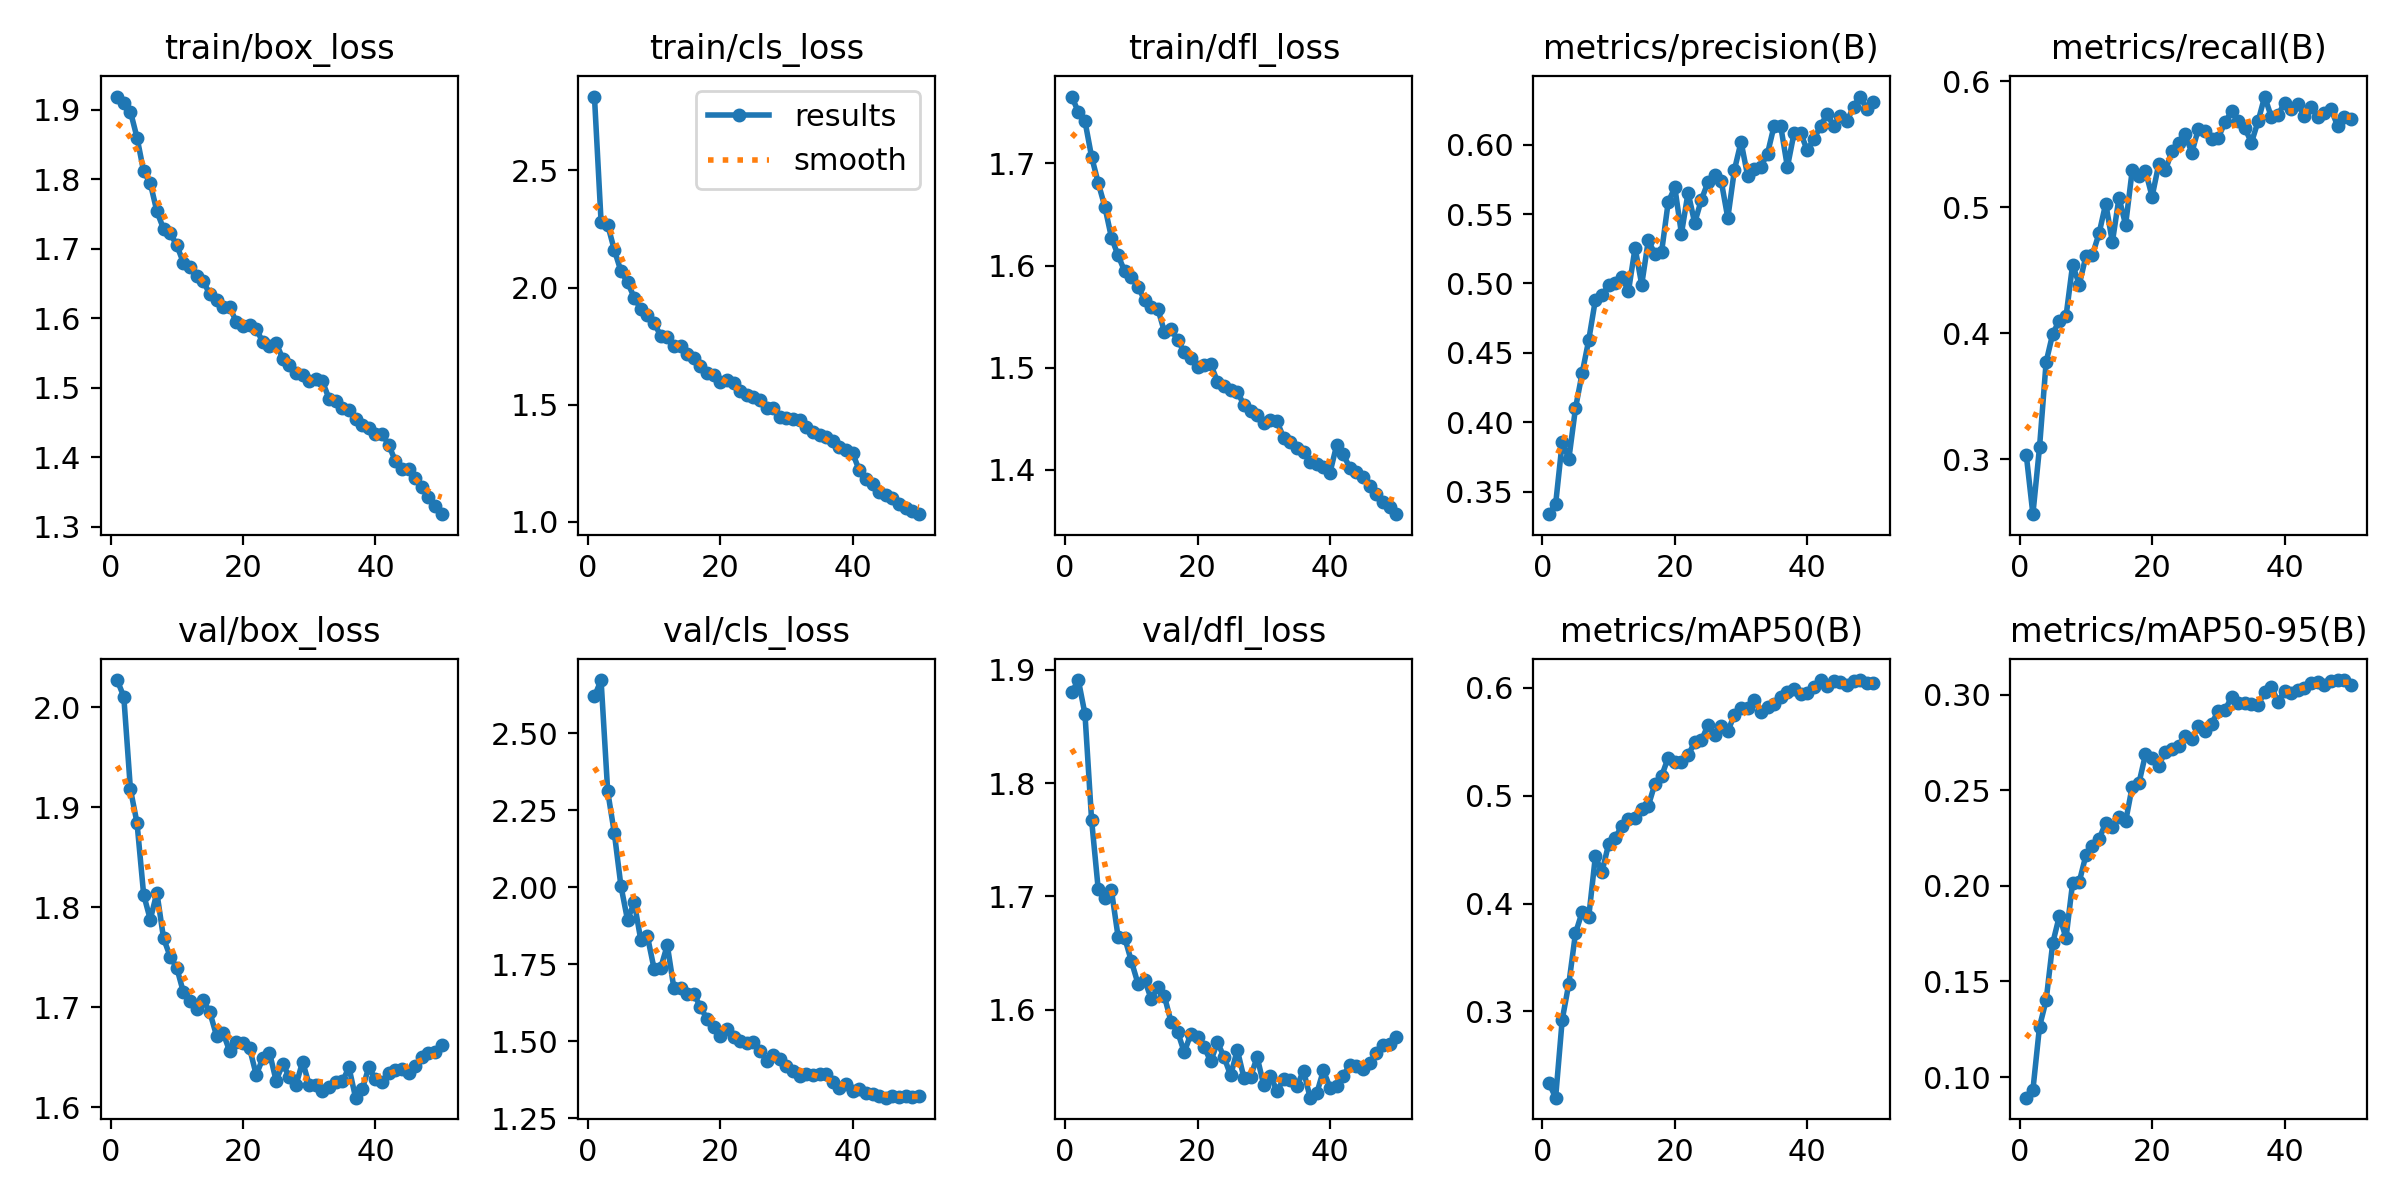


confusion_matrix.png


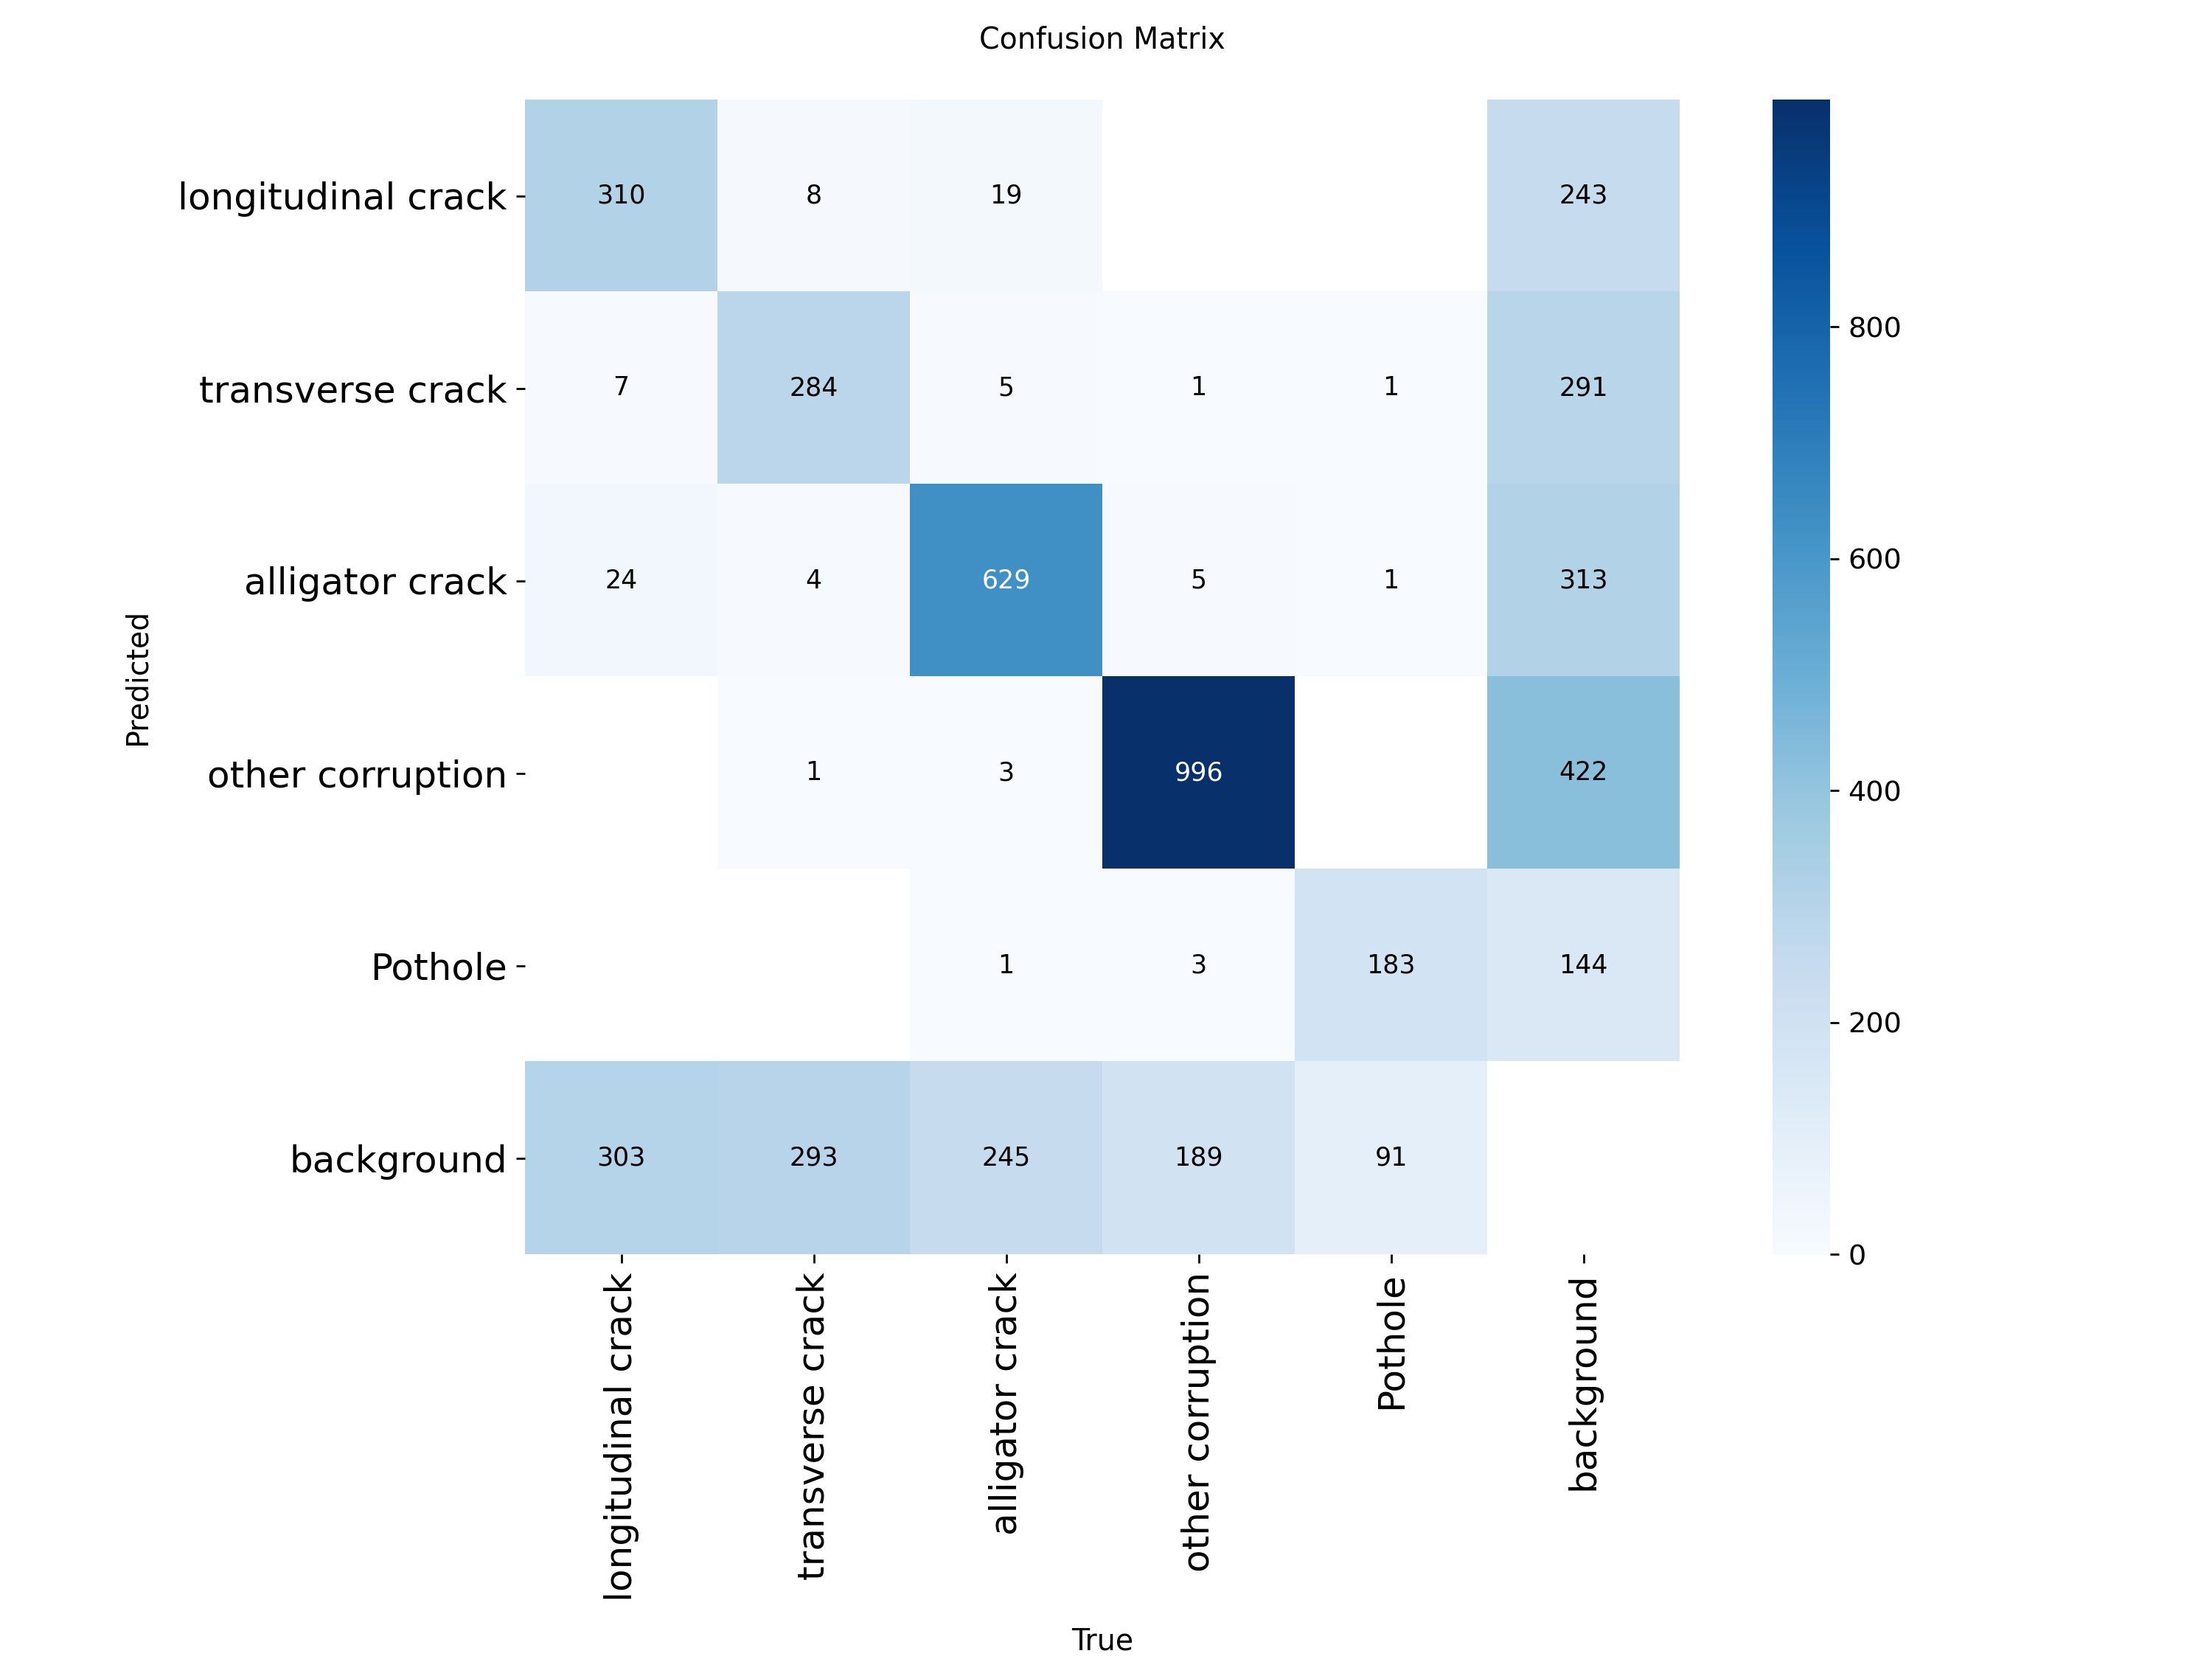


confusion_matrix_normalized.png


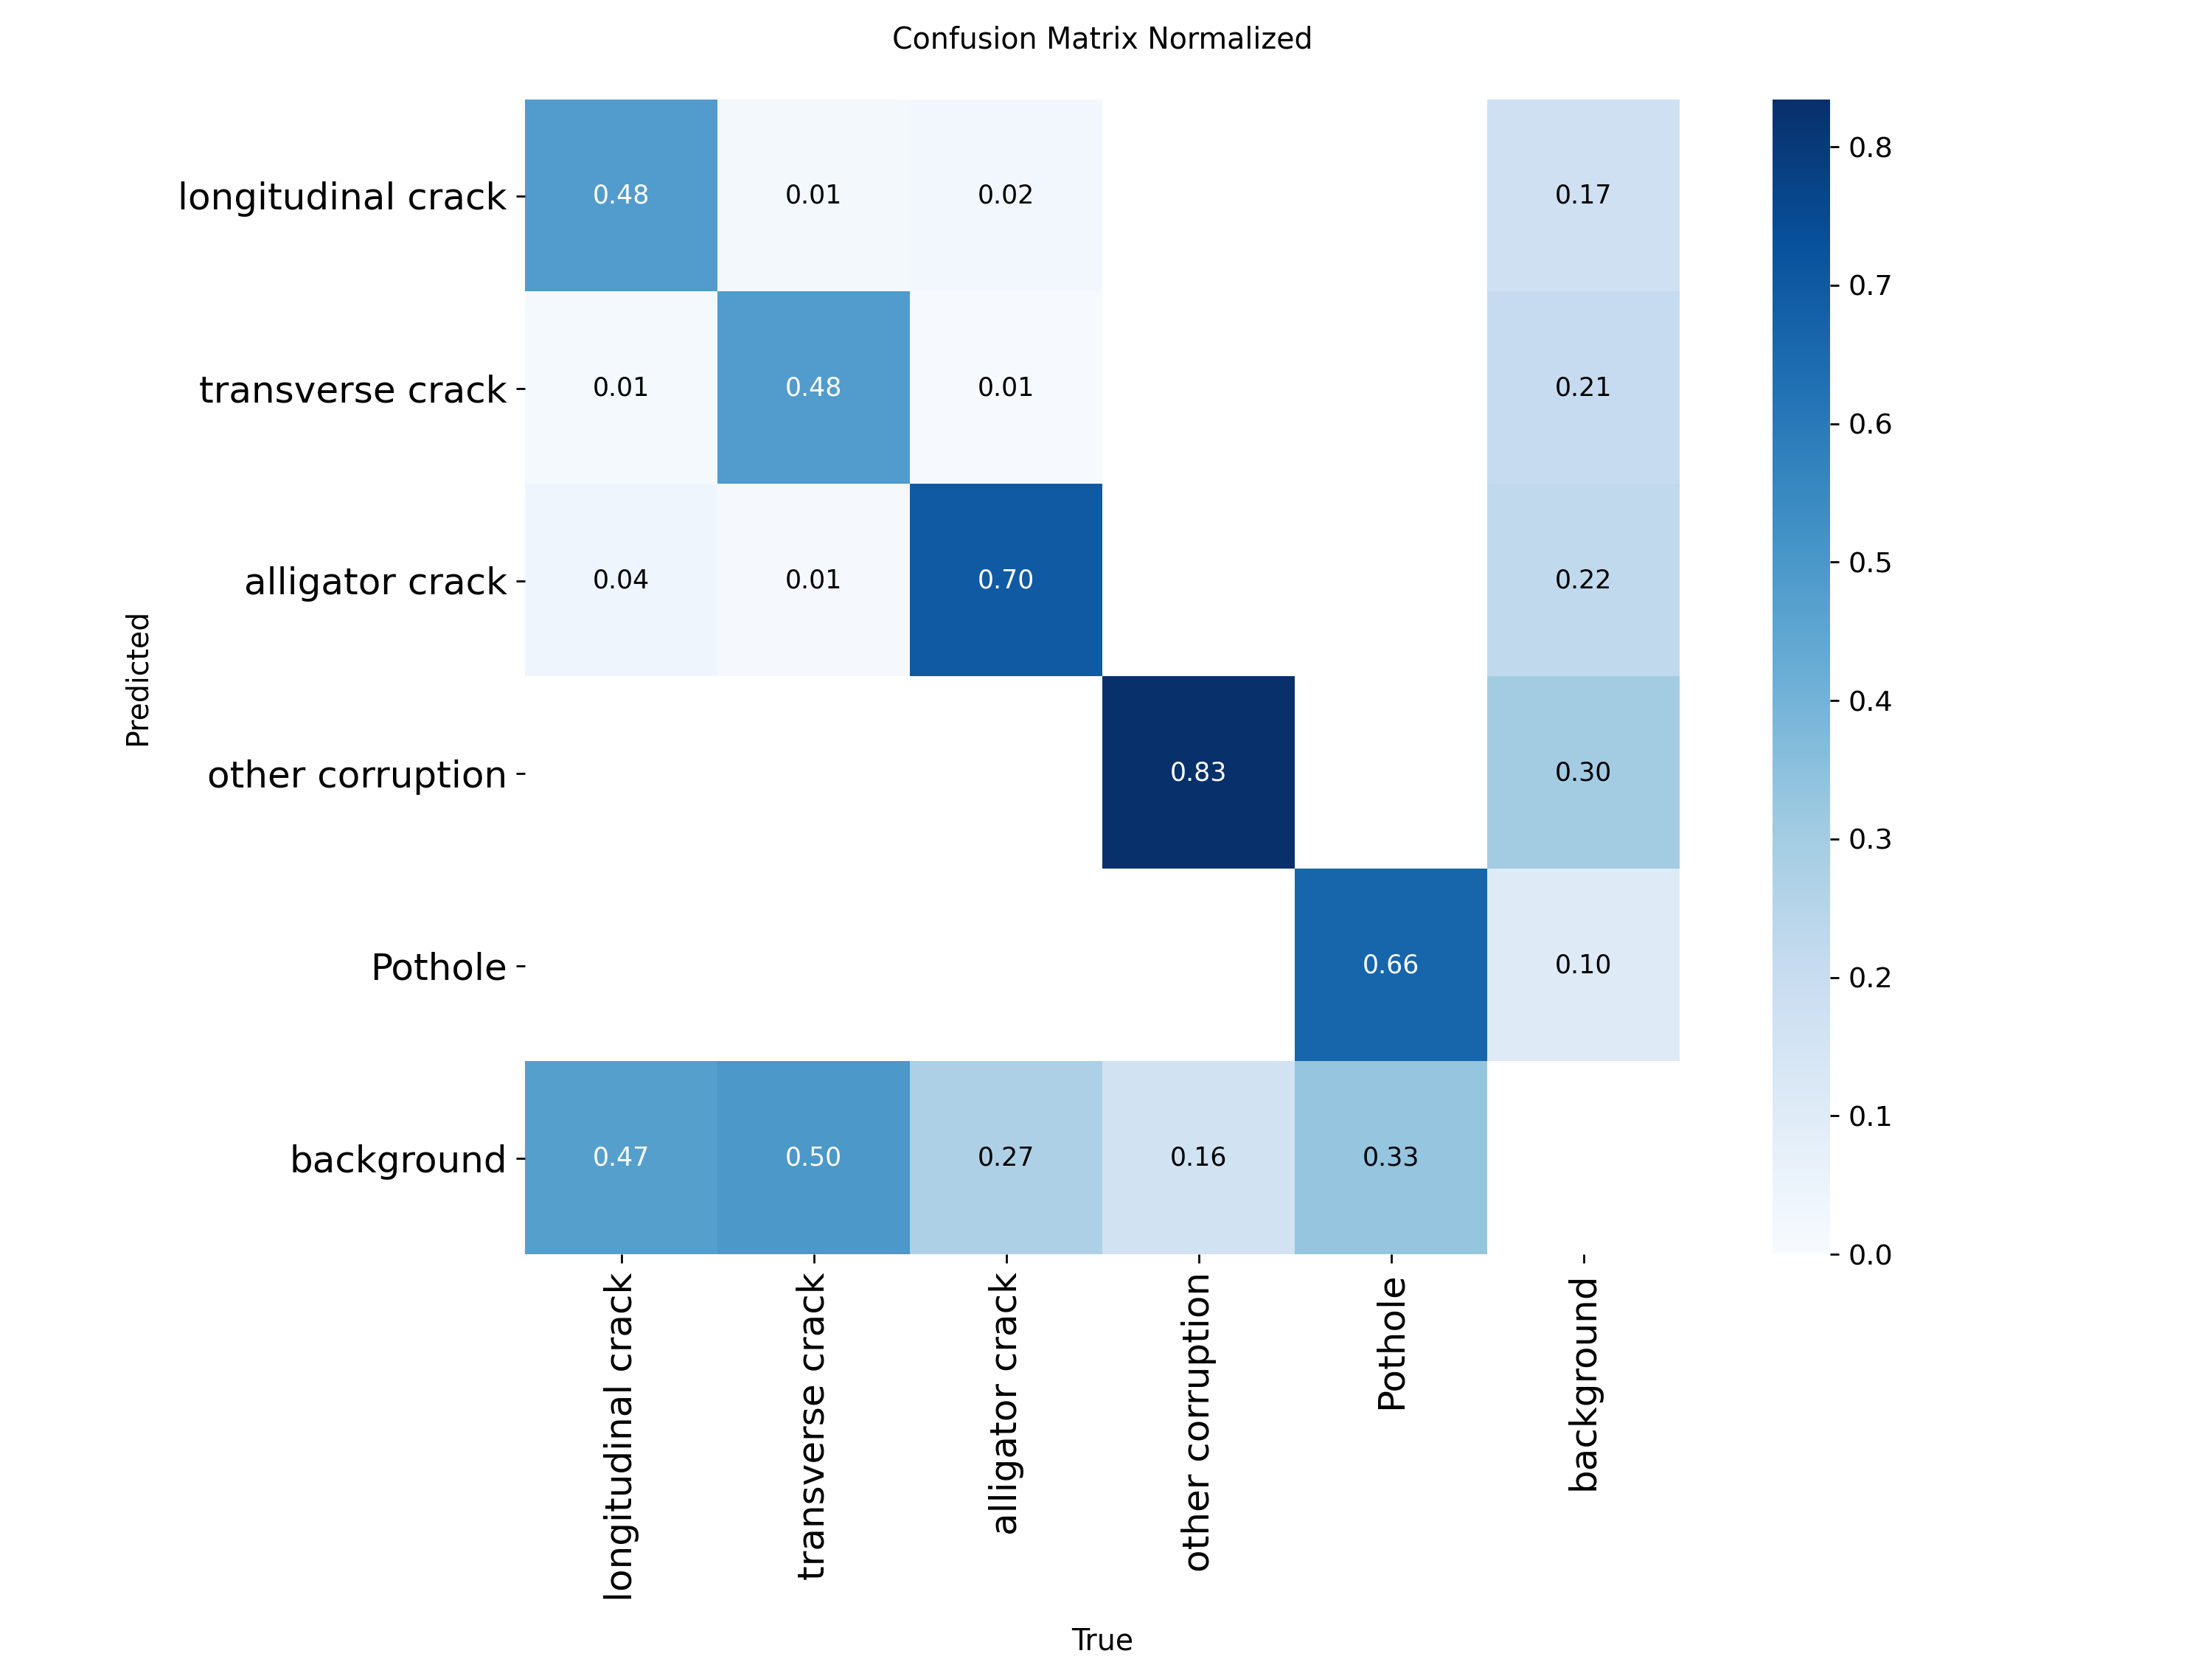


BoxPR_curve.png


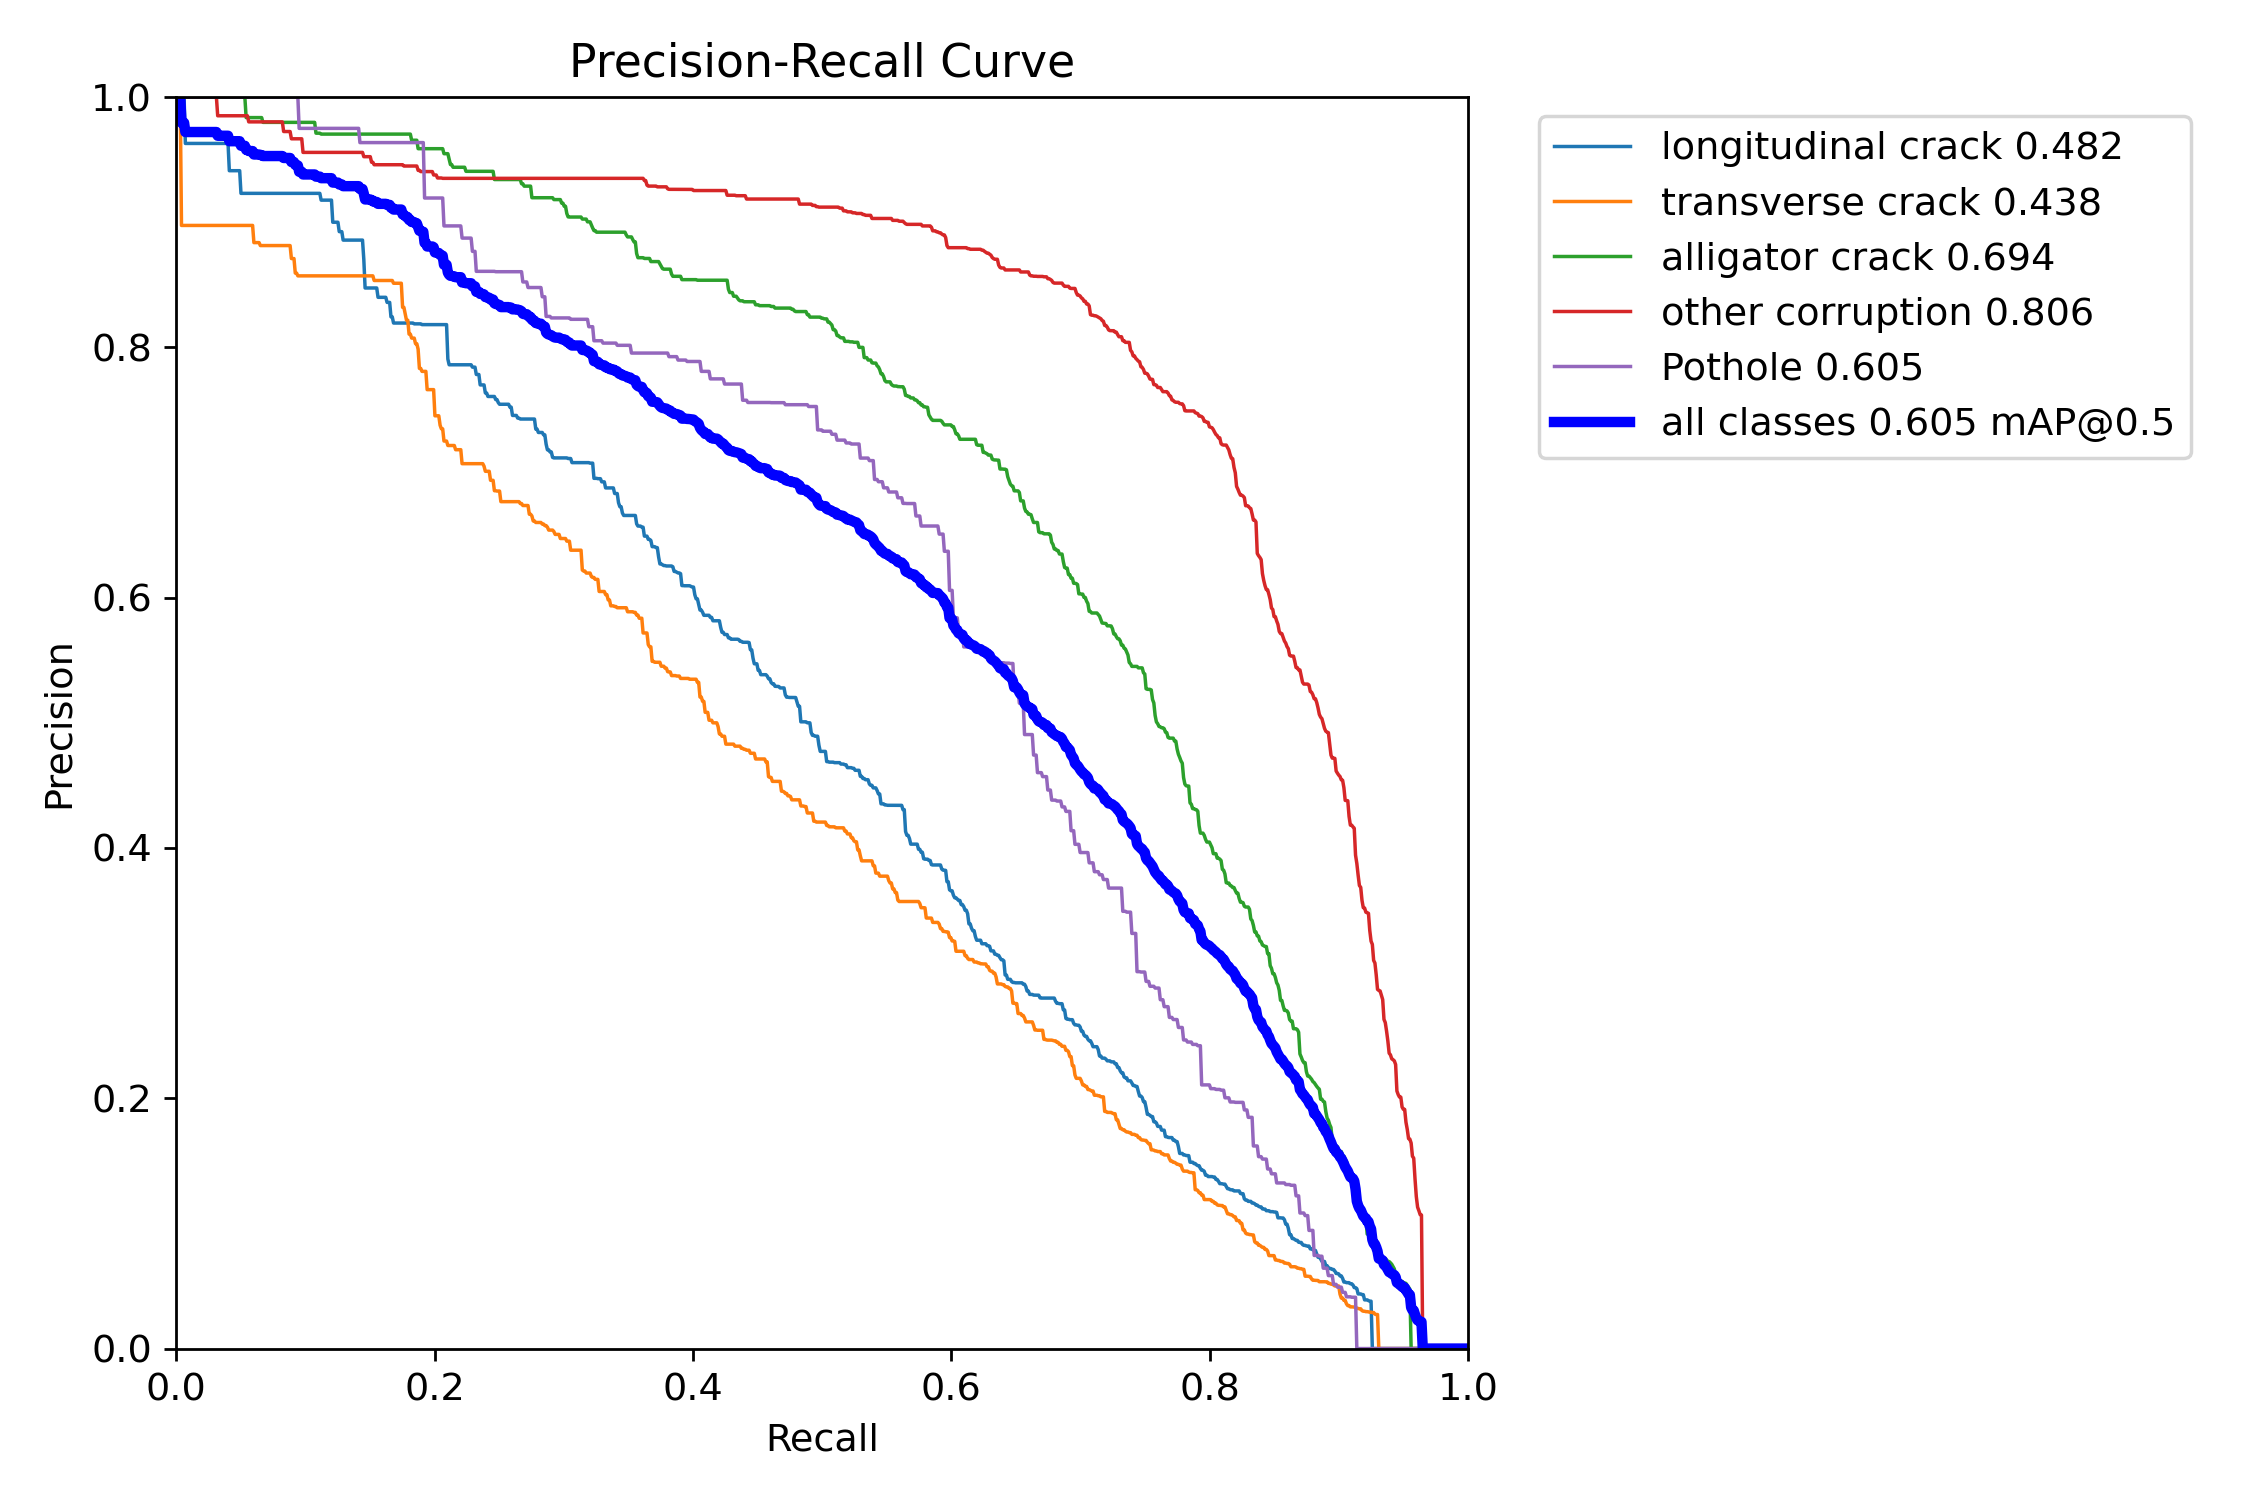


BoxF1_curve.png


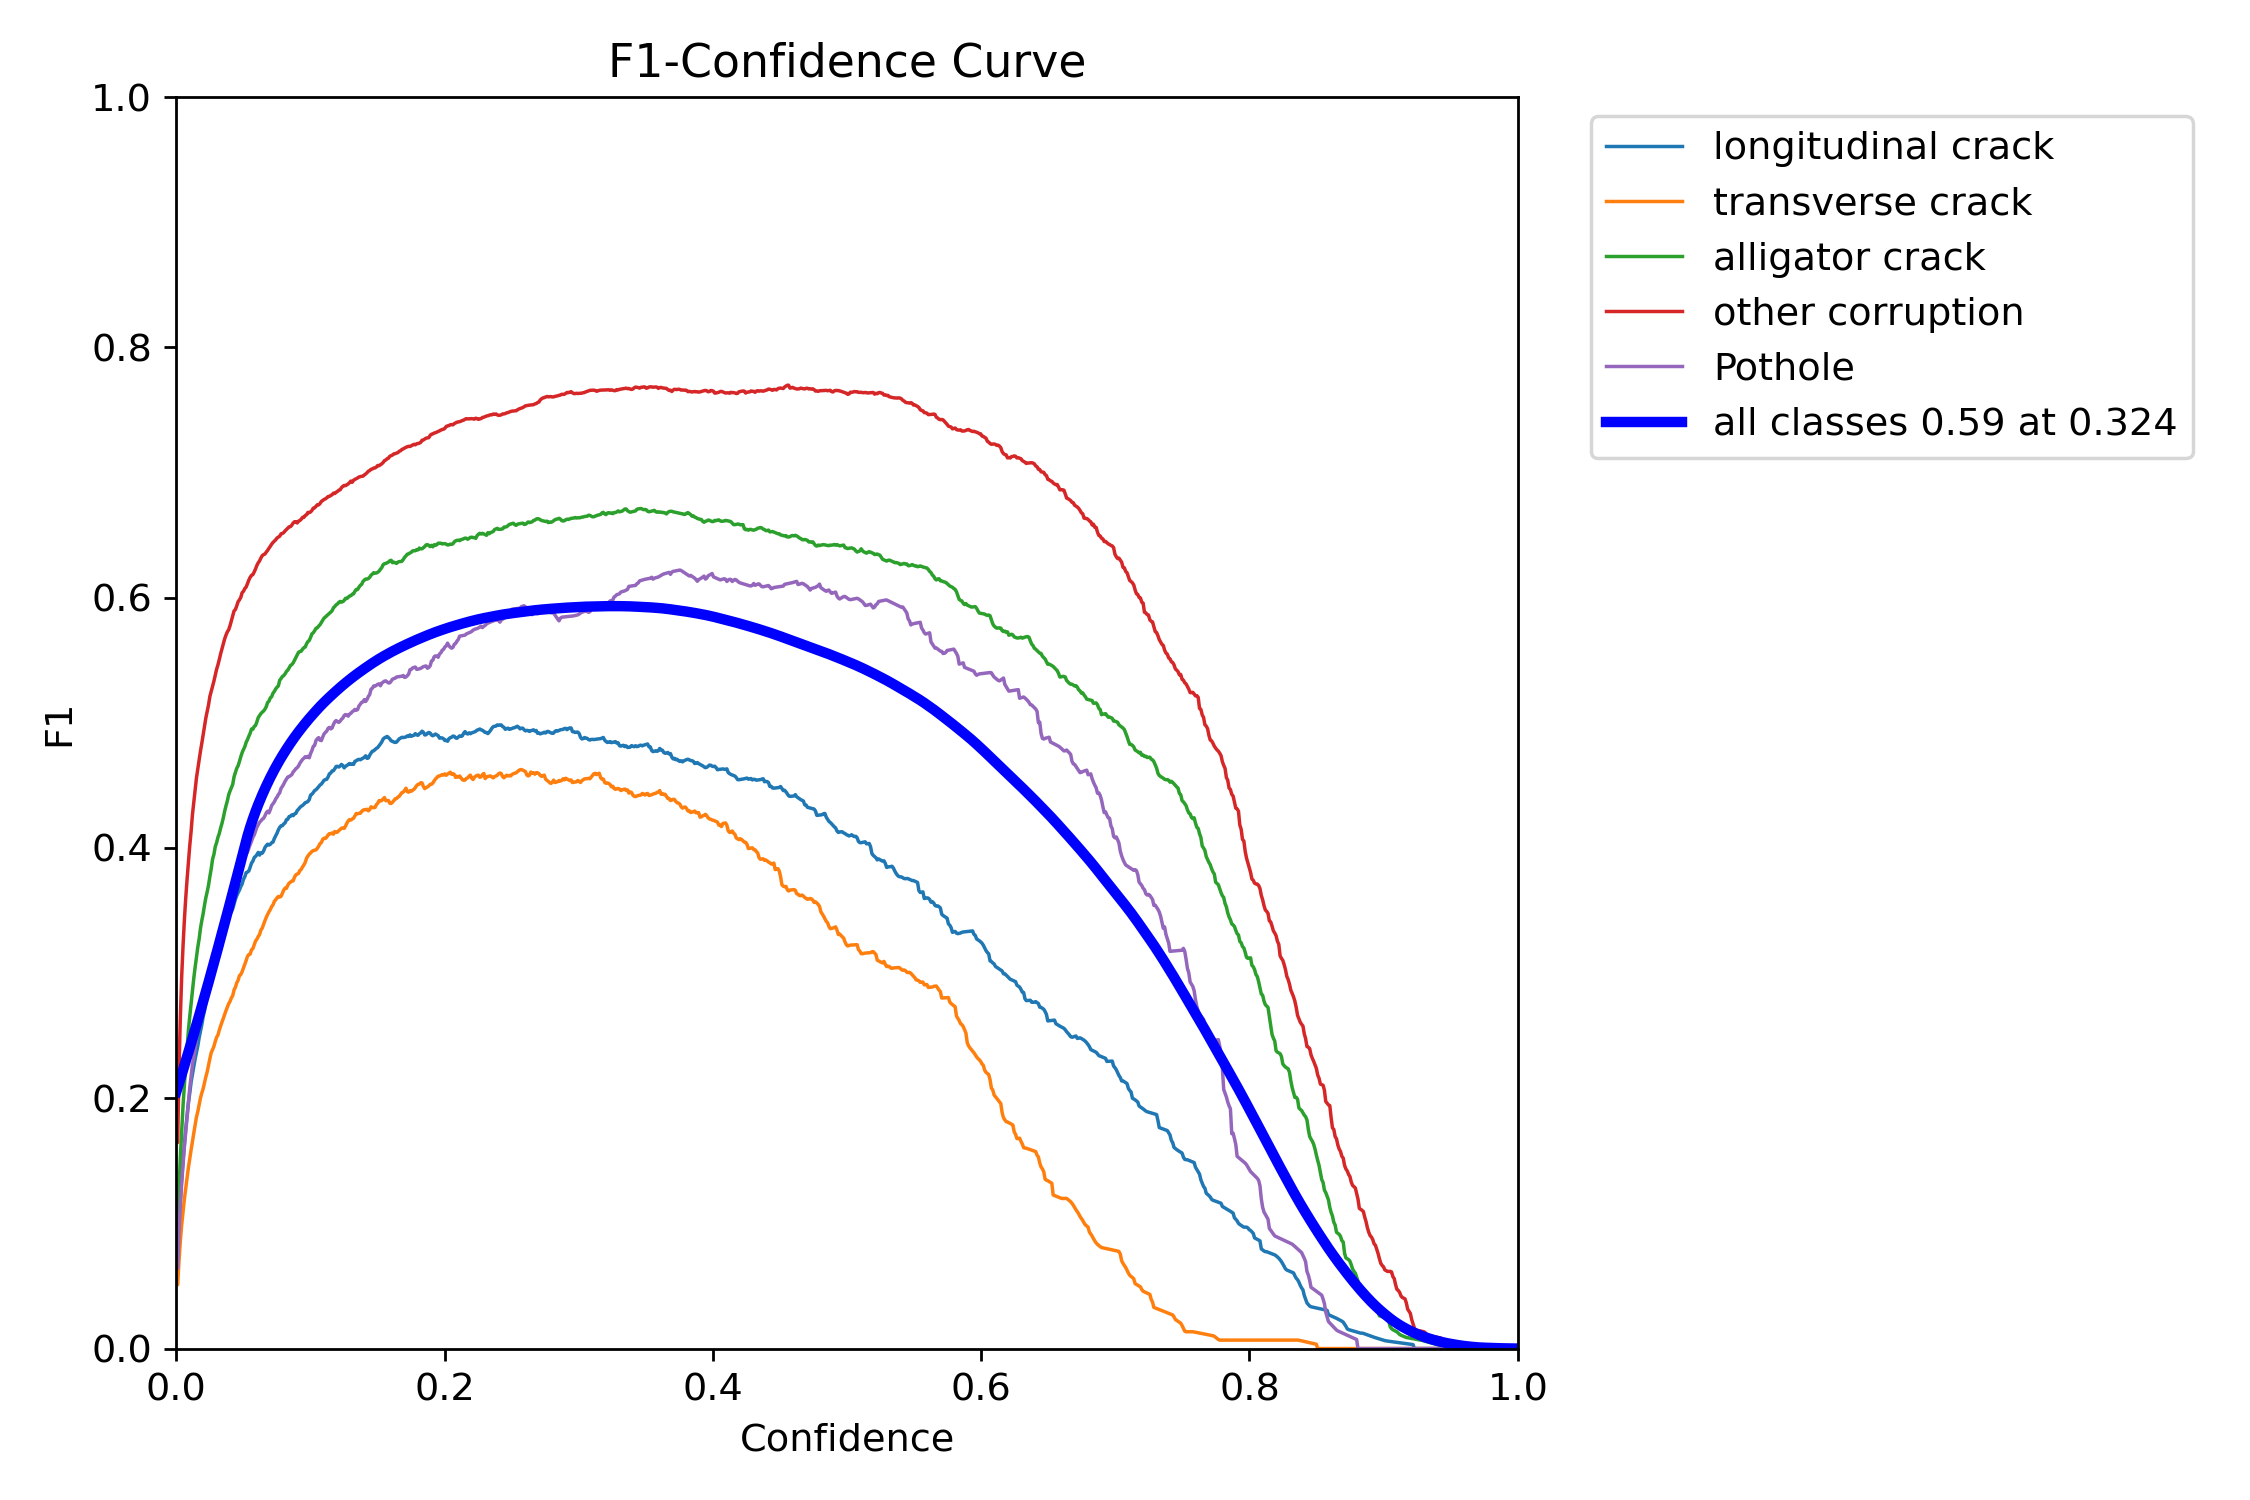


BoxP_curve.png


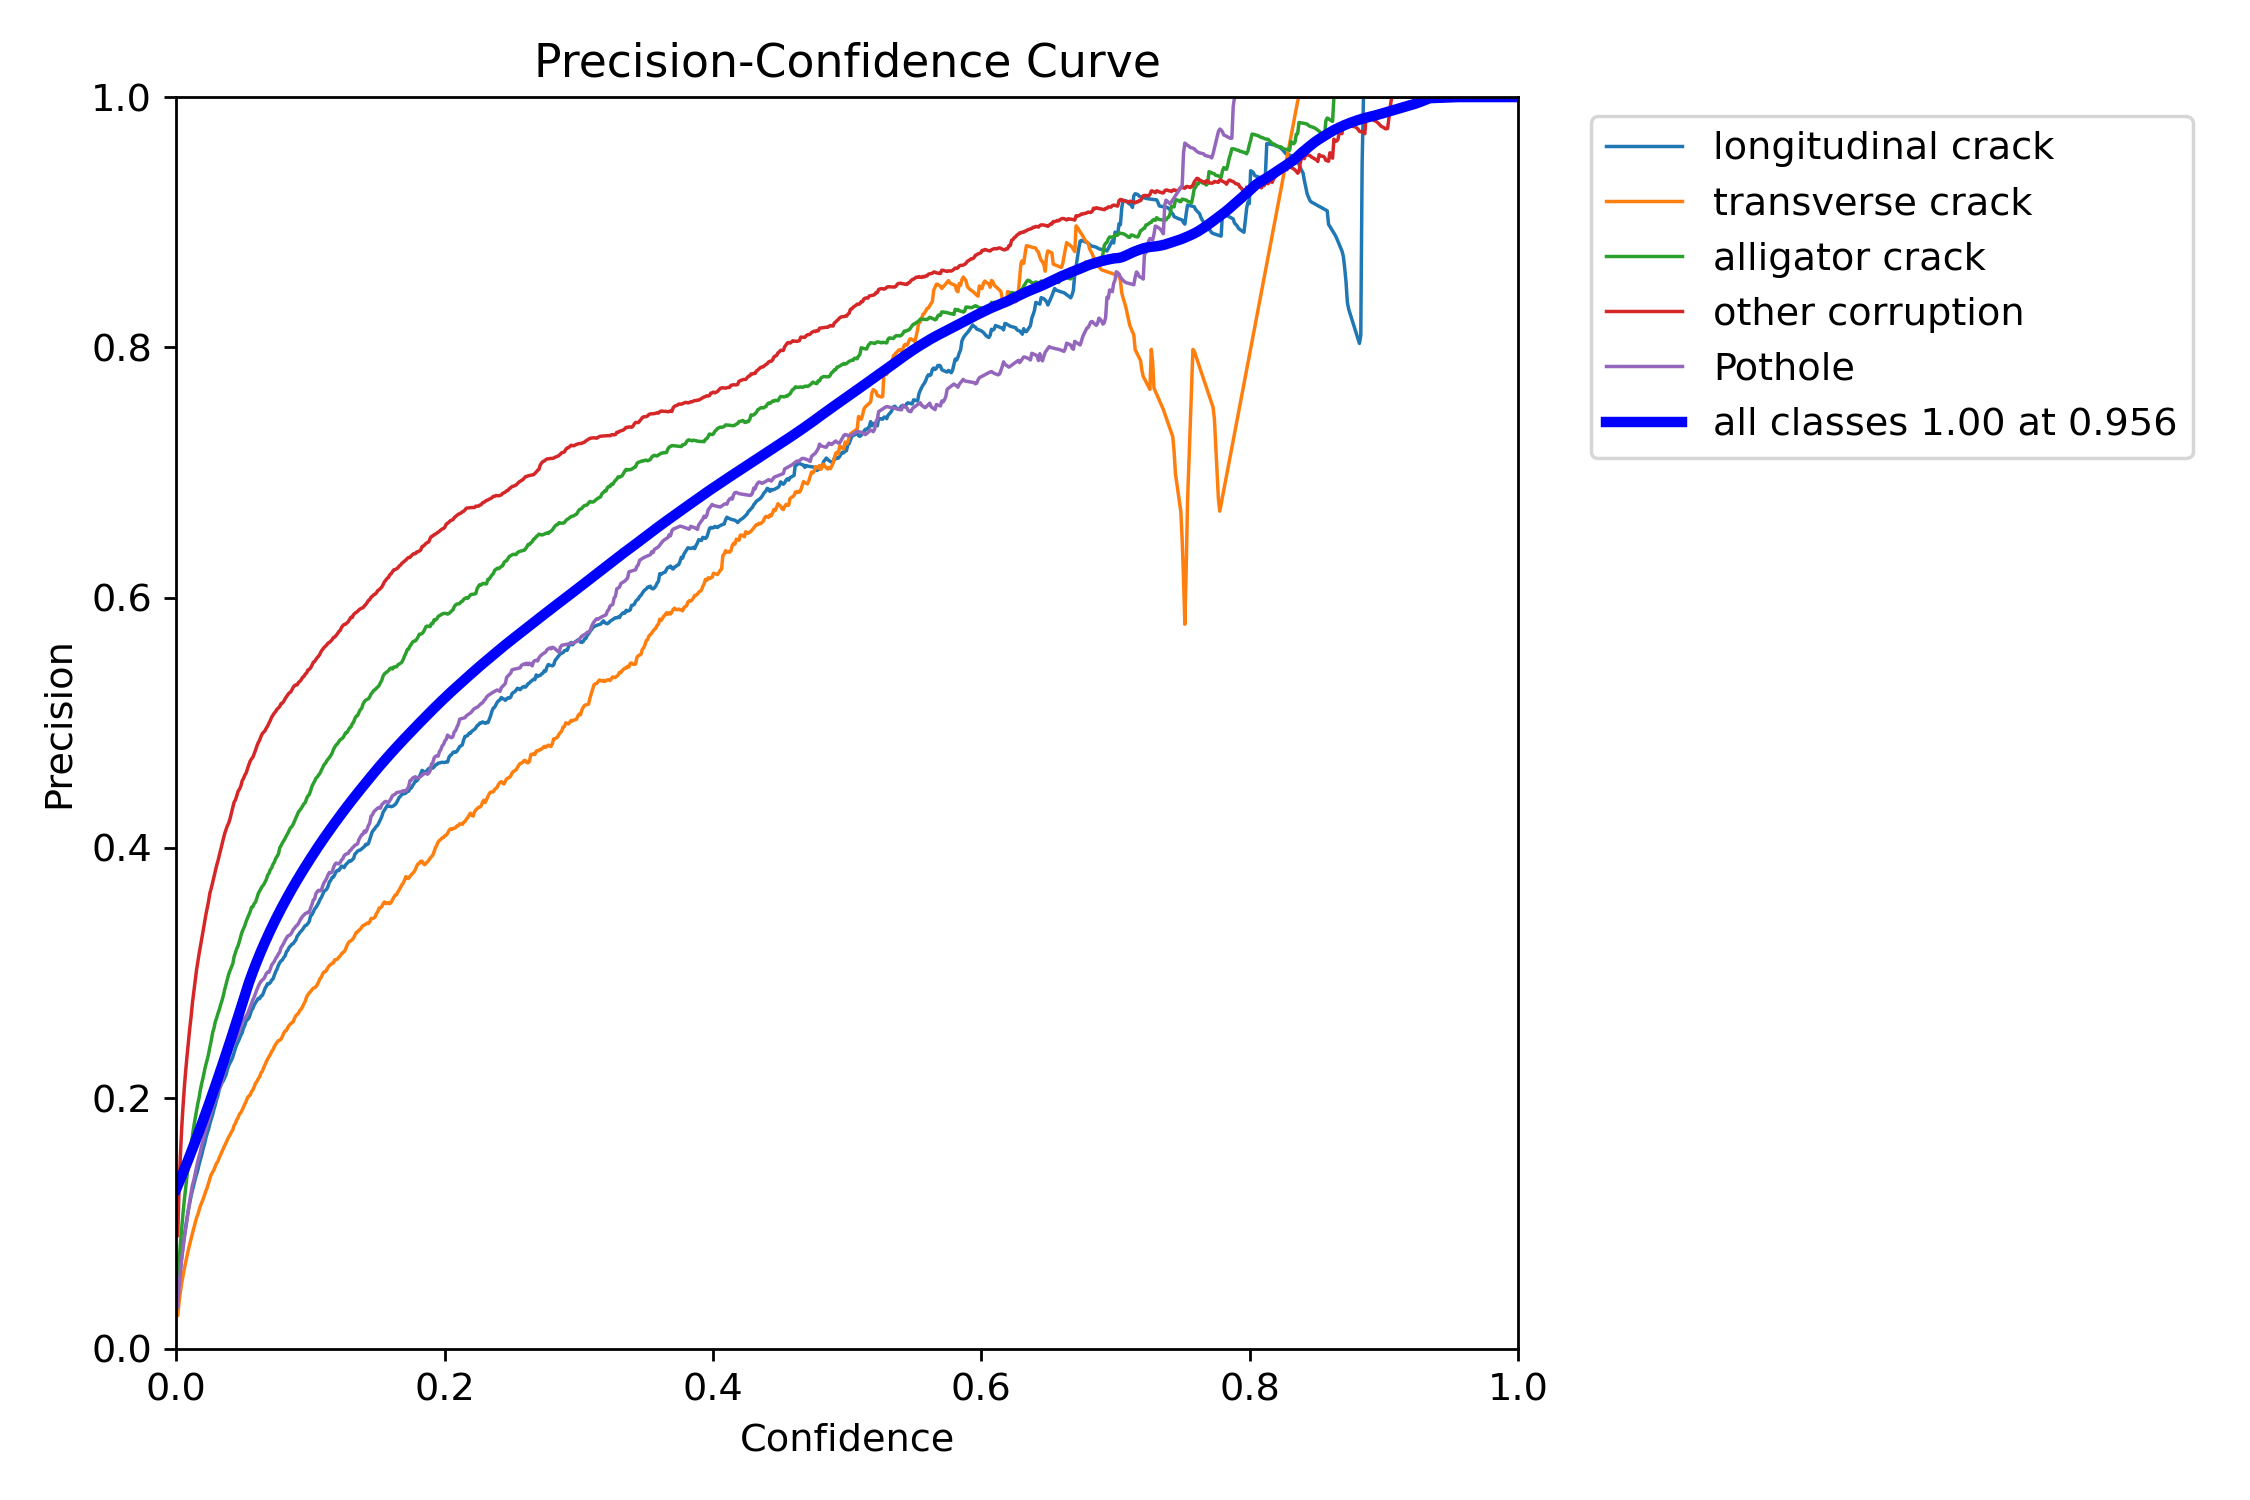


BoxR_curve.png


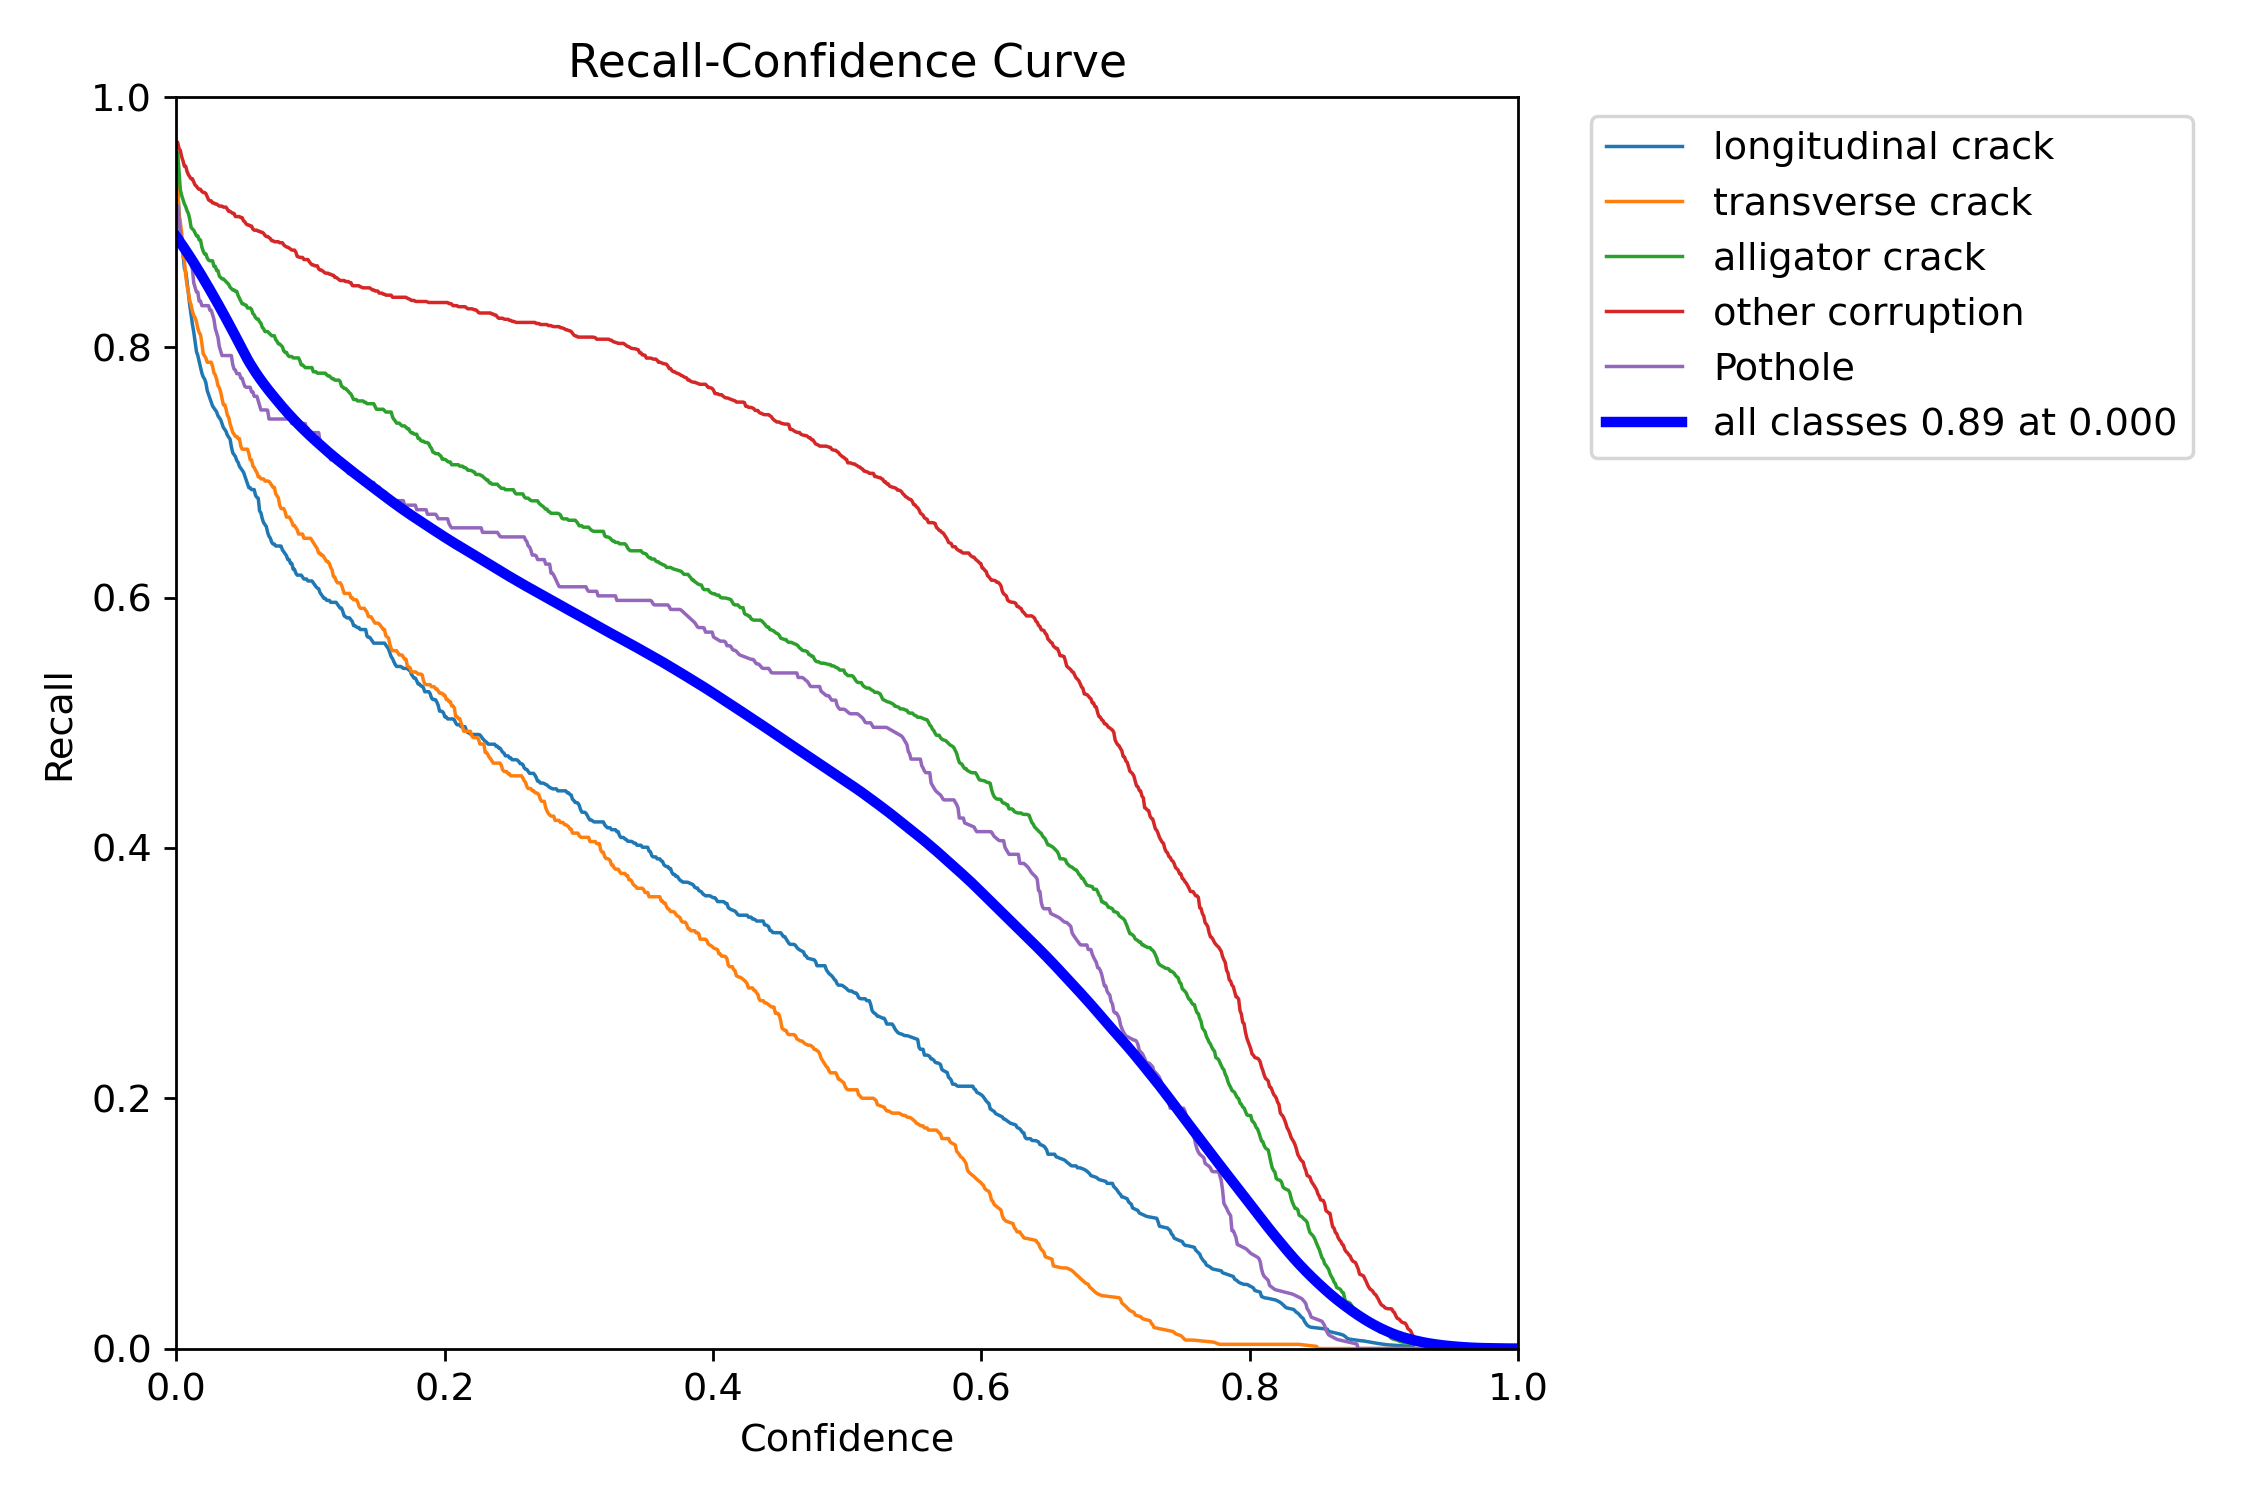


labels.jpg


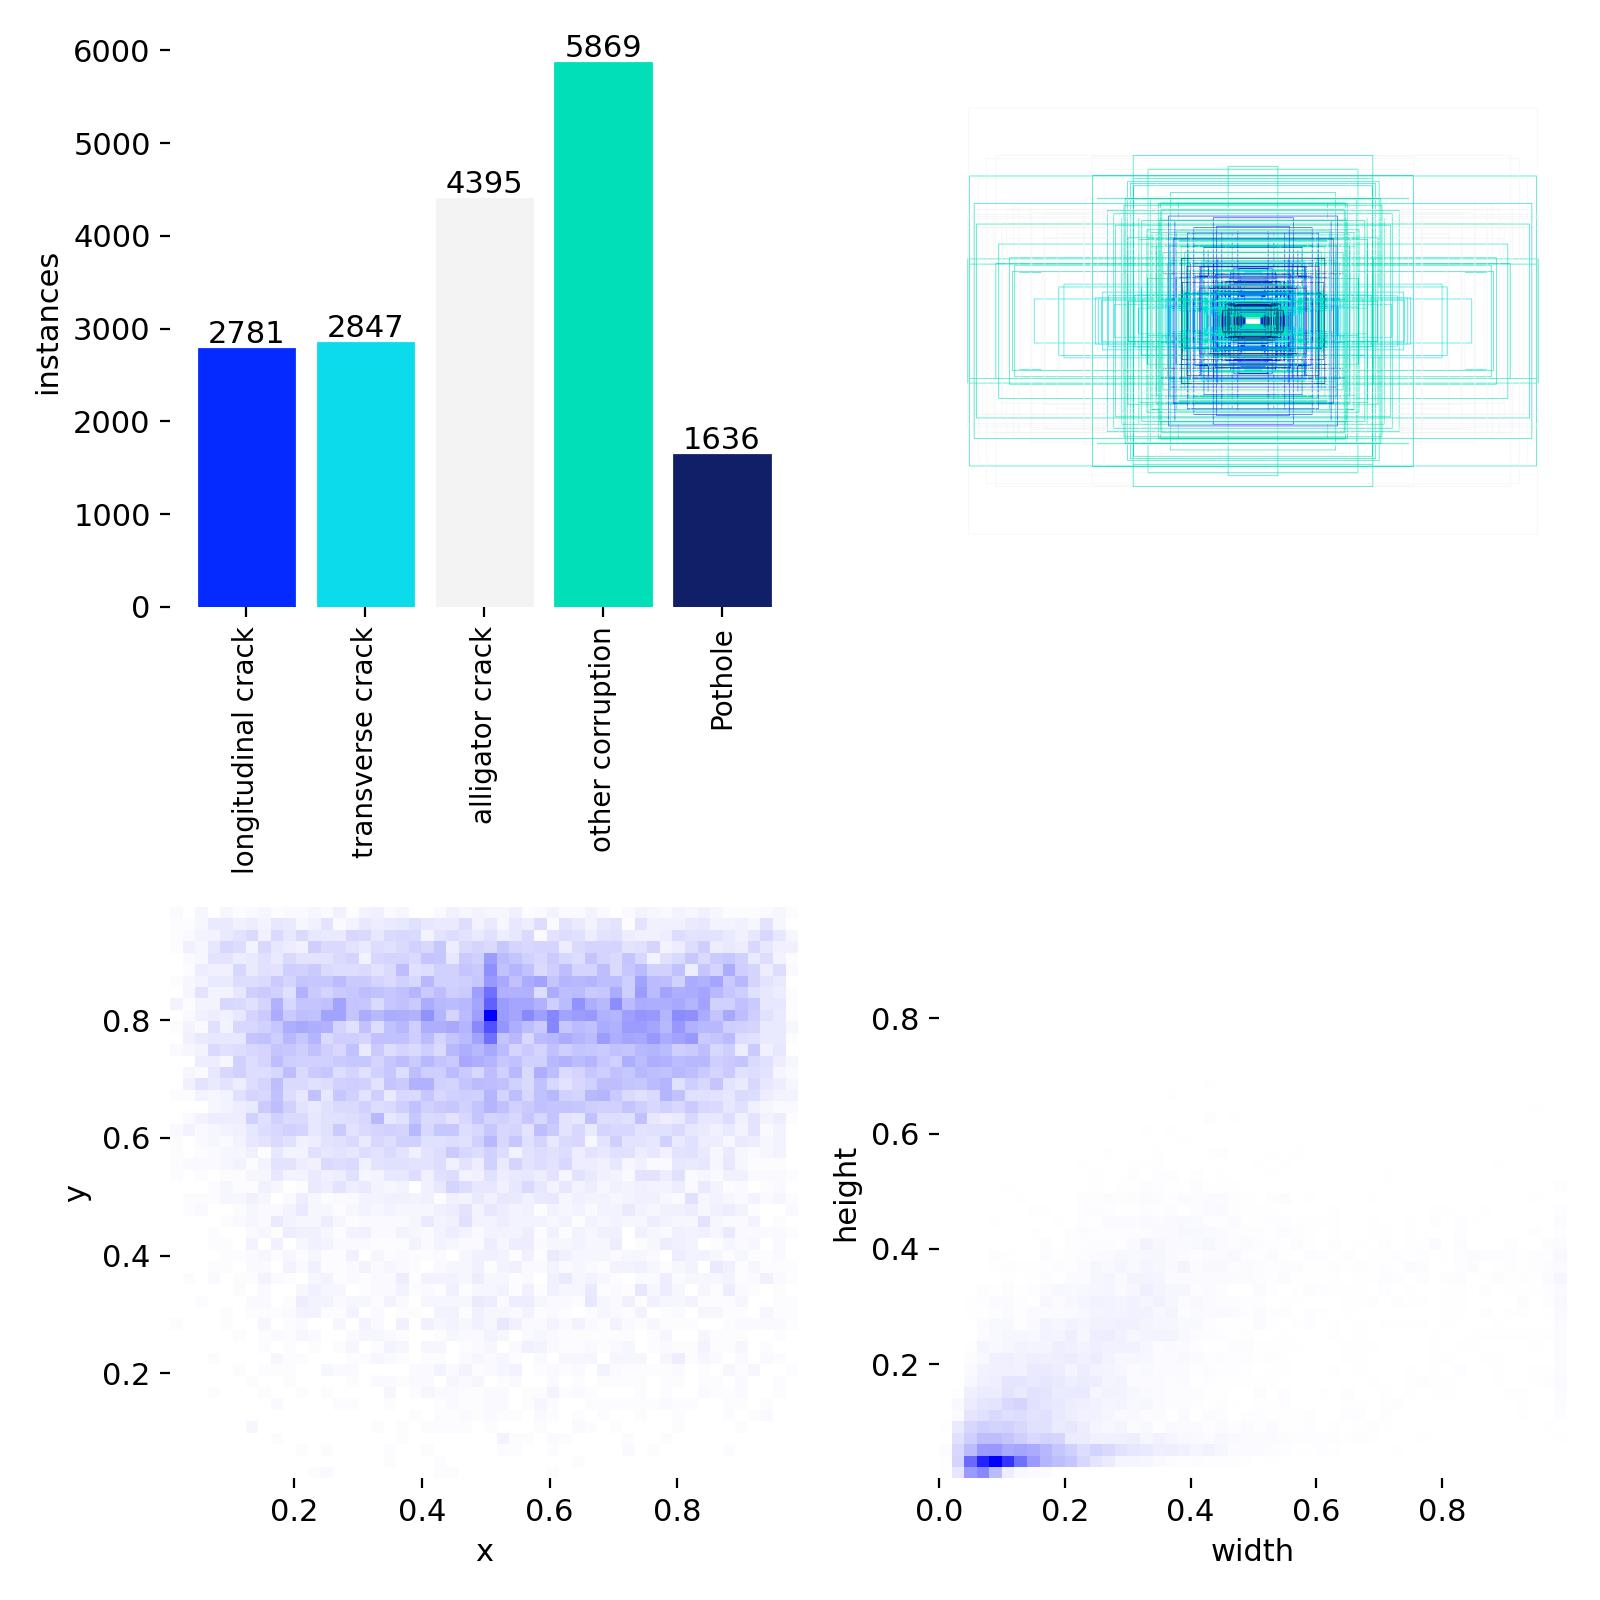

In [23]:
# CELL 14 — Display available training plots
from IPython.display import Image, display

plot_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "labels.jpg",
]

for filename in plot_files:
    path = RUN_DIR / filename
    if path.exists():
        print("\n" + filename)
        display(Image(filename=str(path)))


## 4. Evaluate on each country

Creates one test YAML per country, evaluates the Japan-trained `best.pt` on every country's test set, and saves the overall and per-class results as CSV files.

In [24]:
# CELL 15 — Create a test YAML for each country
COUNTRY_YAMLS = {}

for country in TEST_COUNTRIES:
    yaml_path = WORKING_ROOT / f"test_{country.lower()}.yaml"
    country_yaml = {
        "path": str(COUNTRY_DATASET),
        "train": "train/images",
        "val": "val/images",
        "test": f"test_{country.lower()}/images",
        "nc": 5,
        "names": [
            "longitudinal crack",
            "transverse crack",
            "alligator crack",
            "other corruption",
            "Pothole",
        ],
    }

    with open(yaml_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(country_yaml, f, sort_keys=False)

    COUNTRY_YAMLS[country] = yaml_path

for country, path in COUNTRY_YAMLS.items():
    print(country, "->", path)


Japan -> /kaggle/working/test_japan.yaml
India -> /kaggle/working/test_india.yaml
Czech -> /kaggle/working/test_czech.yaml
Norway -> /kaggle/working/test_norway.yaml
China -> /kaggle/working/test_china.yaml
United -> /kaggle/working/test_united.yaml


In [27]:
# CELL 16 — Evaluate the Japan-trained best model on every country
best_model = YOLO(str(BEST_WEIGHTS))

overall_rows = []
per_class_rows = []

RESULTS_ROOT = WORKING_ROOT / "cross_country_results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

for country in TEST_COUNTRIES:
    print("\n" + "=" * 90)
    print("Evaluating:", country)
    print("=" * 90)

    start = time.time()

    metrics = best_model.val(
        data=str(COUNTRY_YAMLS[country]),
        split="test",
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        plots=True,
        save_json=False,
        project=str(RESULTS_ROOT),
        name=country.lower(),
        exist_ok=True,
    )

    evaluation_seconds = time.time() - start

    inference_ms = metrics.speed["inference"]
    fps = 1000 / inference_ms if inference_ms > 0 else np.nan

    # -----------------------------------------------------
    # Overall country metrics
    # -----------------------------------------------------
    overall_rows.append({
        "Country": country,
        "Seen During Training": "Yes" if country == "Japan" else "No",
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "Inference_ms": inference_ms,
        "FPS": fps,
        "Evaluation_seconds": evaluation_seconds,
    })

    # -----------------------------------------------------
    # Per-class metrics
    #
    # IMPORTANT:
    # metrics.box.p/r/ap50/ap only contain classes that
    # actually occur in that country's ground-truth set.
    #
    # metrics.box.ap_class_index tells us the real class ID.
    # -----------------------------------------------------
    present_class_ids = list(metrics.box.ap_class_index)

    print("Classes present in evaluation:", present_class_ids)

    for metric_index, class_id in enumerate(present_class_ids):

        class_id = int(class_id)

        per_class_rows.append({
            "Country": country,
            "Class ID": class_id,
            "Class Name": metrics.names[class_id],
            "Precision": float(metrics.box.p[metric_index]),
            "Recall": float(metrics.box.r[metric_index]),
            "mAP50": float(metrics.box.ap50[metric_index]),
            "mAP50-95": float(metrics.box.ap[metric_index]),
        })


cross_country_results = pd.DataFrame(overall_rows)
cross_country_per_class = pd.DataFrame(per_class_rows)

print("\nOVERALL CROSS-COUNTRY RESULTS")
display(cross_country_results)

print("\nPER-CLASS RESULTS")
display(cross_country_per_class)


Evaluating: Japan
Ultralytics 8.4.120 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1361.7±623.7 MB/s, size: 114.6 KB)
val: Scanning /kaggle/working/RDD_Japan_Generalization/test_japan/labels.cache... 1524 images, 123 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1524/1524 426.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 96/96 3.8it/s 25.2s0.3ss
                   all       1524       3617      0.601      0.588      0.597      0.296
    longitudinal crack        423        624      0.563      0.462      0.499      0.228
      transverse crack        301        542      0.462      0.428      0.402      0.159
       alligator crack        668        902      0.659      0.636      0.672      0.333
      other corruption        831       1218      0.701      0.799       0

,Country,Seen During Training,Precision,Recall,mAP50,mAP50-95,Inference_ms,FPS,Evaluation_seconds
0,Japan,Yes,0.601244,0.588318,0.596640,0.296455,11.628126,85.998379,28.587346
1,India,No,0.155717,0.159330,0.071058,0.031501,10.476941,95.447710,20.122283
2,Czech,No,0.220773,0.183972,0.112168,0.036347,10.154758,98.476004,9.798587
3,Norway,No,0.209704,0.112856,0.067347,0.024354,5.016410,199.345749,30.874368
4,China,No,0.265586,0.216123,0.158097,0.057556,10.988234,91.006438,15.007348
5,United,No,0.428237,0.492727,0.428214,0.232671,11.603604,86.180119,17.195027



PER-CLASS RESULTS


,Country,Class ID,Class Name,Precision,Recall,mAP50,mAP50-95
0,Japan,0,longitudinal crack,0.562754,0.462015,0.499273,0.227682
1,Japan,1,transverse crack,0.462453,0.428044,0.401784,0.159301
2,Japan,2,alligator crack,0.658696,0.636364,0.671709,0.332735
3,Japan,3,other corruption,0.701389,0.798851,0.790285,0.475978
4,Japan,4,Pothole,0.620931,0.616314,0.620149,0.286576
5,India,0,longitudinal crack,0.089023,0.069869,0.022117,0.009246
6,India,1,transverse crack,0.008750,0.142857,0.003991,0.000708
7,India,2,alligator crack,0.260449,0.192308,0.128500,0.053475
8,India,3,other corruption,0.148751,0.238806,0.089973,0.047525
9,India,4,Pothole,0.271612,0.152809,0.110709,0.046550


In [28]:
# CELL 17 — Save overall and per-class CSVs
OVERALL_CSV = RESULTS_ROOT / "cross_country_overall.csv"
PER_CLASS_CSV = RESULTS_ROOT / "cross_country_per_class.csv"

cross_country_results.to_csv(OVERALL_CSV, index=False)
cross_country_per_class.to_csv(PER_CLASS_CSV, index=False)

print("Saved:", OVERALL_CSV)
print("Saved:", PER_CLASS_CSV)


Saved: /kaggle/working/cross_country_results/cross_country_overall.csv
Saved: /kaggle/working/cross_country_results/cross_country_per_class.csv


## 5. Generalization analysis and charts

Calculates how much the mAP drops compared with Japan and plots the overall metrics, the mAP@0.5:0.95 per country, the drop relative to Japan and the per-class mAP. The Czech, Norway and United States test sets have no "other corruption" annotations, so those cells are empty in the per-class table. Finally it prints the best and worst unseen country.

In [29]:
# CELL 18 — Generalization drop relative to Japan
japan = cross_country_results[
    cross_country_results["Country"] == "Japan"
].iloc[0]

drop_rows = []

for _, row in cross_country_results.iterrows():
    drop_rows.append({
        "Country": row["Country"],
        "Seen During Training": row["Seen During Training"],
        "mAP50": row["mAP50"],
        "mAP50-95": row["mAP50-95"],
        "mAP50 Drop vs Japan": japan["mAP50"] - row["mAP50"],
        "mAP50-95 Drop vs Japan": japan["mAP50-95"] - row["mAP50-95"],
    })

generalization_drop = pd.DataFrame(drop_rows)
display(generalization_drop)

generalization_drop.to_csv(
    RESULTS_ROOT / "generalization_drop_vs_japan.csv",
    index=False
)


,Country,Seen During Training,mAP50,mAP50-95,mAP50 Drop vs Japan,mAP50-95 Drop vs Japan
0,Japan,Yes,0.596640,0.296455,0.000000,0.000000
1,India,No,0.071058,0.031501,0.525582,0.264954
2,Czech,No,0.112168,0.036347,0.484472,0.260108
3,Norway,No,0.067347,0.024354,0.529293,0.272101
4,China,No,0.158097,0.057556,0.438543,0.238899
5,United,No,0.428214,0.232671,0.168426,0.063784


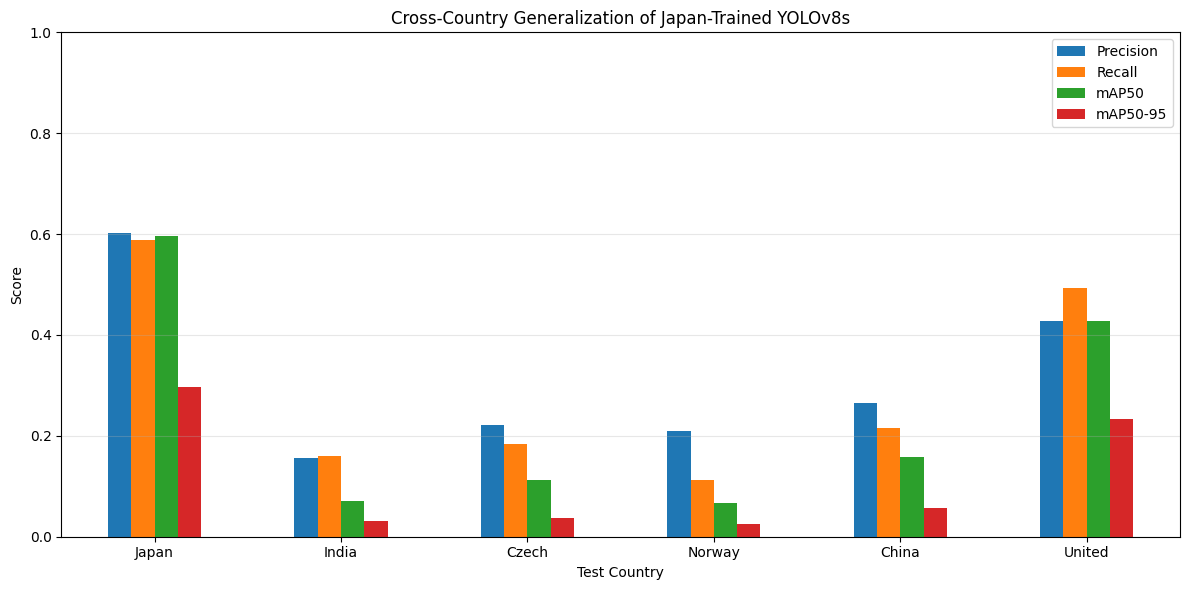

Saved: /kaggle/working/cross_country_results/cross_country_metrics.png


In [30]:
# CELL 19 — Overall metric comparison chart
plot_df = cross_country_results.set_index("Country")[
    ["Precision", "Recall", "mAP50", "mAP50-95"]
]

ax = plot_df.plot(kind="bar", figsize=(12, 6))
plt.title("Cross-Country Generalization of Japan-Trained YOLOv8s")
plt.xlabel("Test Country")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

out = RESULTS_ROOT / "cross_country_metrics.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out)


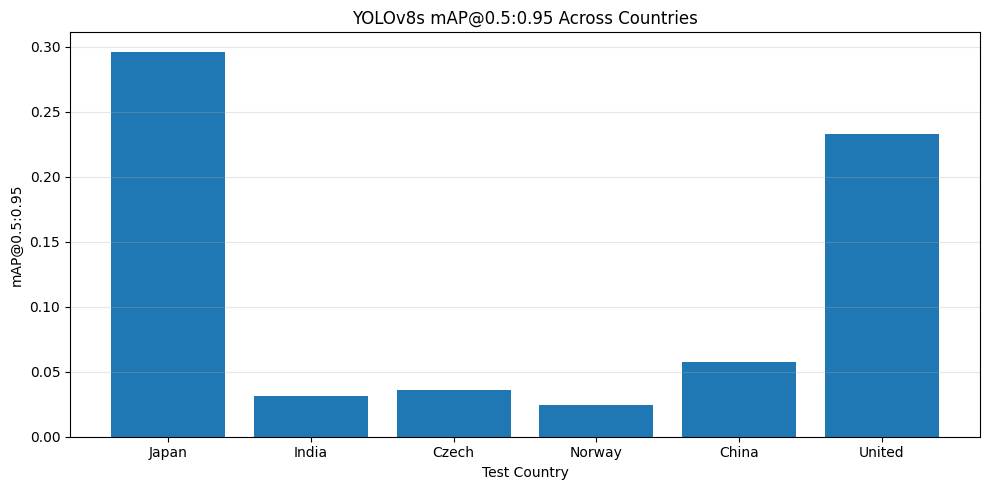

Saved: /kaggle/working/cross_country_results/map5095_by_country.png


In [31]:
# CELL 20 — mAP50-95 by country
plt.figure(figsize=(10, 5))
plt.bar(
    cross_country_results["Country"],
    cross_country_results["mAP50-95"]
)
plt.title("YOLOv8s mAP@0.5:0.95 Across Countries")
plt.xlabel("Test Country")
plt.ylabel("mAP@0.5:0.95")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

out = RESULTS_ROOT / "map5095_by_country.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out)


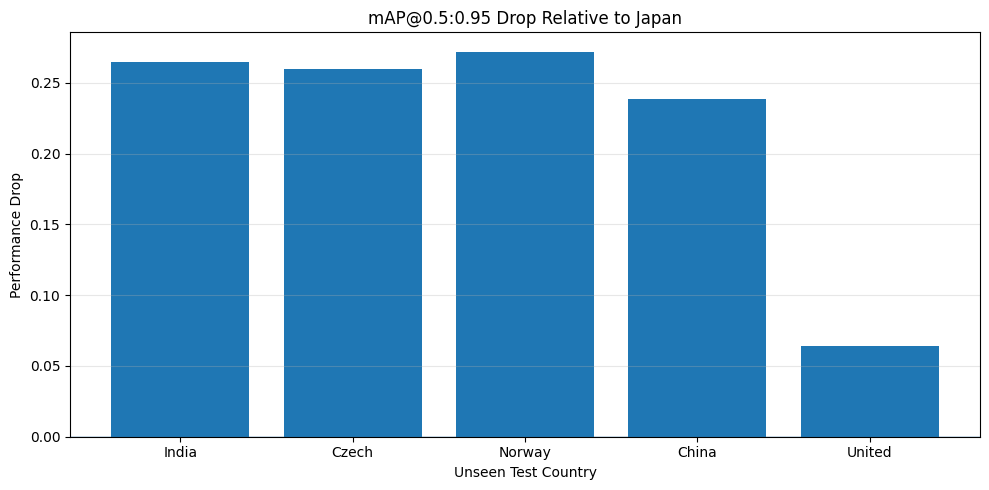

Saved: /kaggle/working/cross_country_results/generalization_drop.png


In [32]:
# CELL 21 — Generalization drop chart
plot_drop = generalization_drop[
    generalization_drop["Country"] != "Japan"
].copy()

plt.figure(figsize=(10, 5))
plt.bar(
    plot_drop["Country"],
    plot_drop["mAP50-95 Drop vs Japan"]
)
plt.axhline(0, linewidth=1)
plt.title("mAP@0.5:0.95 Drop Relative to Japan")
plt.xlabel("Unseen Test Country")
plt.ylabel("Performance Drop")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

out = RESULTS_ROOT / "generalization_drop.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out)


In [33]:
# CELL 22 — Per-class mAP50-95 across countries
per_class_map = cross_country_per_class.pivot(
    index="Class Name",
    columns="Country",
    values="mAP50-95"
)

display(per_class_map)

per_class_map.to_csv(
    RESULTS_ROOT / "per_class_map5095_by_country.csv"
)


Country,China,Czech,India,Japan,Norway,United
Class Name,,,,,,
Pothole,0.038688,0.018694,0.046550,0.286576,0.000830,0.157393
alligator crack,0.111161,0.027091,0.053475,0.332735,0.021017,0.308869
longitudinal crack,0.059576,0.063538,0.009246,0.227682,0.055431,0.314143
other corruption,0.000067,NaN,0.047525,0.475978,NaN,NaN
transverse crack,0.078287,0.036062,0.000708,0.159301,0.020137,0.150279


In [35]:
# CELL 23 — Best and worst unseen-country generalization
unseen = cross_country_results[
    cross_country_results["Country"] != "Japan"
].copy()

best_unseen = unseen.loc[unseen["mAP50-95"].idxmax()]
worst_unseen = unseen.loc[unseen["mAP50-95"].idxmin()]

print(f"Japan mAP50-95: {japan['mAP50-95']:.4f}")
print(
    f"Best unseen country: {best_unseen['Country']} "
    f"({best_unseen['mAP50-95']:.4f})"
)
print(
    f"Worst unseen country: {worst_unseen['Country']} "
    f"({worst_unseen['mAP50-95']:.4f})"
)
print(
    f"Average unseen-country mAP50-95: "
    f"{unseen['mAP50-95'].mean():.4f}"
)
print(
    f"Average unseen-country mAP50: "
    f"{unseen['mAP50'].mean():.4f}"
)


Japan mAP50-95: 0.2965
Best unseen country: United (0.2327)
Worst unseen country: Norway (0.0244)
Average unseen-country mAP50-95: 0.0765
Average unseen-country mAP50: 0.1674


## 6. Outputs and cleanup

Lists the generated files, then deletes the large temporary folders and backup zip files from Kaggle's working directory.

In [36]:
# CELL 24 — List generated files
print("Training outputs:")
for path in sorted(RUN_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(RUN_DIR))

print("\nCross-country outputs:")
for path in sorted(RESULTS_ROOT.rglob("*")):
    if path.is_file():
        print(path.relative_to(RESULTS_ROOT))


Training outputs:
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch18600.jpg
train_batch18601.jpg
train_batch18602.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights/best.pt
weights/epoch0.pt
weights/epoch10.pt
weights/epoch15.pt
weights/epoch20.pt
weights/epoch25.pt
weights/epoch30.pt
weights/epoch35.pt
weights/epoch40.pt
weights/epoch45.pt
weights/epoch5.pt
weights/last.pt

Cross-country outputs:
china/BoxF1_curve.png
china/BoxPR_curve.png
china/BoxP_curve.png
china/BoxR_curve.png
china/confusion_matrix.png
china/confusion_matrix_normalized.png
china/val_batch0_labels.jpg
china/val_batch0_pred.jpg
china/val_batch1_labels.jpg
china/val_batch1_pred.jpg
china/val_batch2_labels.jpg
china/val_batch2_pred.jpg
cross_country_metrics.png

In [41]:
from pathlib import Path
import shutil

paths_to_remove = [
    "/kaggle/working/RDD_Japan_Generalization",
    "/kaggle/working/RDD_Japan_Generalization.zip",
    "/kaggle/working/YOLOv8s_JapanOnly_backup.zip",
    "/kaggle/working/CrossCountry_results_backup.zip",
]

print("Cleaning temporary files...\n")

for p in paths_to_remove:
    path = Path(p)

    if path.is_dir():
        shutil.rmtree(path)
        print(f"Removed folder: {path}")

    elif path.is_file():
        path.unlink()
        print(f"Removed file: {path}")

    else:
        print(f"Not found (already removed): {path}")

print("\nCleanup completed.")

Cleaning temporary files...

Not found (already removed): /kaggle/working/RDD_Japan_Generalization
Removed file: /kaggle/working/RDD_Japan_Generalization.zip
Removed file: /kaggle/working/YOLOv8s_JapanOnly_backup.zip
Removed file: /kaggle/working/CrossCountry_results_backup.zip

Cleanup completed.
